LOADING DATASET

Dataset loaded successfully!
Total articles: 38514

Dataset columns:
['title', 'text', 'subject', 'date', 'label']

Label distribution:
label
0    21196
1    17318
Name: count, dtype: int64

Label meaning:
0 = Real
1 = Fake

CREATING DOCUMENTS

Dataset after duplicate removal: 38512

CREATING BALANCED DATASET

Selected dataset size: 7500

Class distribution:
label
0    3750
1    3750
Name: count, dtype: int64

TRAIN-TEST SPLIT

Training set: 6000
Testing set: 1500

Training distribution:
label
0    3000
1    3000
Name: count, dtype: int64

Testing distribution:
label
0    750
1    750
Name: count, dtype: int64

SETTING UP NLTK

Calculating sentence count...

Creating sentence distribution graph...


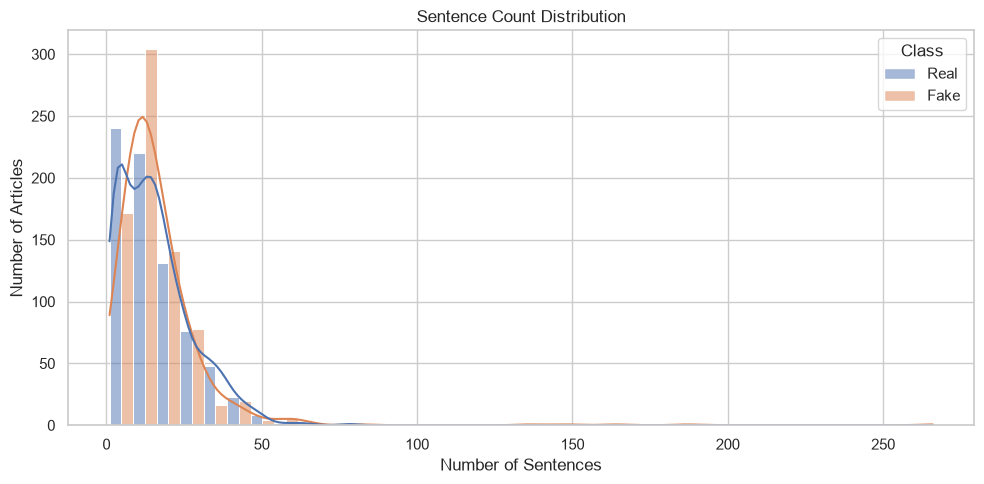


DATA PREPARATION COMPLETE

LOADING SPACY
spaCy model loaded successfully!

TESTING FEATURE EXTRACTION

Sample linguistic features:
word_count: 74
sentence_count: 2
character_count: 478
average_word_length: 5.337837837837838
average_sentence_length: 37.0
noun_count: 10
verb_count: 11
adjective_count: 5
adverb_count: 0
pronoun_count: 5
proper_noun_count: 18
exclamation_count: 0
question_count: 0
uppercase_count: 1
url_count: 0
hashtag_count: 0
mention_count: 0
special_character_count: 11
repeated_word_count: 8

Linguistic feature extraction test complete!

PROCESSING TRAINING DATA
This may take a few minutes...
Training features extracted!

PROCESSING TEST DATA
Testing features extracted!

LINGUISTIC FEATURES COMPLETE

Training feature shape: (6000, 20)
Testing feature shape: (1500, 20)

Number of linguistic features: 19

Feature columns:
['word_count', 'sentence_count', 'character_count', 'average_word_length', 'average_sentence_length', 'noun_count', 'verb_count', 'adjective_count', '

In [1]:
# =========================================================
# FAKE NEWS DETECTION - DATA PREPARATION + FEATURE EXTRACTION
# =========================================================

# =========================================================
# 1. IMPORT LIBRARIES
# =========================================================

import pandas as pd
import numpy as np
import re
import string
import os
import pickle
import json
import nltk

from collections import Counter
from nltk.tokenize import sent_tokenize, word_tokenize

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import spacy


# =========================================================
# SETTINGS
# =========================================================

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


# =========================================================
# 2. LOAD CLEANED DATASET
# =========================================================

print("================================")
print("LOADING DATASET")
print("================================")

df = pd.read_csv(
    '../data/processed/news_clean.csv'
)

print("\nDataset loaded successfully!")
print("Total articles:", len(df))

print("\nDataset columns:")
print(df.columns.tolist())


# =========================================================
# 3. CONVERT LABELS
# =========================================================

# Original dataset:
# 0 = Fake
# 1 = Real
#
# For this implementation:
# 0 = Real
# 1 = Fake

df['label'] = df['label'].map({
    0: 1,   # Fake -> 1
    1: 0    # Real -> 0
})


print("\nLabel distribution:")
print(df['label'].value_counts())

print("\nLabel meaning:")
print("0 = Real")
print("1 = Fake")


# =========================================================
# 4. CREATE DOCUMENT
# =========================================================

print("\n================================")
print("CREATING DOCUMENTS")
print("================================")

df['title'] = df['title'].fillna('')
df['text'] = df['text'].fillna('')

df['document'] = (
    df['title'] + ' ' + df['text']
).str.strip()


# Remove empty documents

df = df[
    df['document'] != ''
].reset_index(drop=True)


# Remove duplicate articles

df = df.drop_duplicates(
    subset=['document']
).reset_index(drop=True)


print(
    "\nDataset after duplicate removal:",
    len(df)
)


# =========================================================
# 5. CREATE BALANCED DATASET
# =========================================================

print("\n================================")
print("CREATING BALANCED DATASET")
print("================================")


# Real news

real_sample = (
    df[df['label'] == 0]
    .sample(
        n=3750,
        random_state=RANDOM_STATE
    )
)


# Fake news

fake_sample = (
    df[df['label'] == 1]
    .sample(
        n=3750,
        random_state=RANDOM_STATE
    )
)


# Combine

df_sample = pd.concat(
    [
        real_sample,
        fake_sample
    ],
    ignore_index=True
)


# Shuffle

df_sample = (
    df_sample
    .sample(
        frac=1.0,
        random_state=RANDOM_STATE
    )
    .reset_index(drop=True)
)


print(
    "\nSelected dataset size:",
    len(df_sample)
)


print("\nClass distribution:")

print(
    df_sample['label'].value_counts()
)


# =========================================================
# 6. TRAIN-TEST SPLIT
# =========================================================

print("\n================================")
print("TRAIN-TEST SPLIT")
print("================================")


train_df, test_df = train_test_split(
    df_sample,
    test_size=0.20,
    train_size=0.80,
    random_state=RANDOM_STATE,
    stratify=df_sample['label']
)


# Reset indexes

train_df = train_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)


print(
    "\nTraining set:",
    len(train_df)
)

print(
    "Testing set:",
    len(test_df)
)


print("\nTraining distribution:")

print(
    train_df['label'].value_counts()
)


print("\nTesting distribution:")

print(
    test_df['label'].value_counts()
)


# =========================================================
# 7. NLTK SETUP
# =========================================================

print("\n================================")
print("SETTING UP NLTK")
print("================================")


nltk.download(
    'punkt',
    quiet=True
)

nltk.download(
    'punkt_tab',
    quiet=True
)


# =========================================================
# 8. SENTENCE COUNT
# =========================================================

print("\nCalculating sentence count...")


test_df['sentence_count'] = (
    test_df['document']
    .apply(
        lambda x:
        len(sent_tokenize(x))
        if isinstance(x, str)
        else 0
    )
)


# Convert numerical label to class name

test_df['Class'] = test_df[
    'label'
].map({
    0: 'Real',
    1: 'Fake'
})


# =========================================================
# 9. VISUALIZE SENTENCE DISTRIBUTION
# =========================================================

print("\nCreating sentence distribution graph...")


plt.figure(
    figsize=(10, 5)
)


sns.histplot(
    data=test_df,
    x='sentence_count',
    hue='Class',
    kde=True,
    bins=35,
    multiple='dodge'
)


plt.title(
    'Sentence Count Distribution'
)


plt.xlabel(
    'Number of Sentences'
)


plt.ylabel(
    'Number of Articles'
)


plt.tight_layout()

plt.show()


# =========================================================
# 10. DATA PREPARATION COMPLETE
# =========================================================

print("\n================================")
print("DATA PREPARATION COMPLETE")
print("================================")


# =========================================================
# 11. LOAD SPACY MODEL
# =========================================================

print("\n================================")
print("LOADING SPACY")
print("================================")


# NER is disabled because we are not currently
# using named entity features.
# This makes processing faster.

nlp = spacy.load(
    "en_core_web_sm",
    disable=["ner"]
)


print("spaCy model loaded successfully!")


# =========================================================
# 12. LINGUISTIC FEATURE EXTRACTION FUNCTION
# =========================================================

def extract_linguistic_features(doc):

    """
    Extract grammar, linguistic and anomaly
    features from a spaCy Doc object.
    """

    # -----------------------------------------------------
    # Original text
    # -----------------------------------------------------

    text = doc.text


    # -----------------------------------------------------
    # POS FEATURES
    # -----------------------------------------------------

    noun_count = 0

    verb_count = 0

    adjective_count = 0

    adverb_count = 0

    pronoun_count = 0

    proper_noun_count = 0


    for token in doc:

        if token.pos_ == "NOUN":

            noun_count += 1


        elif token.pos_ == "VERB":

            verb_count += 1


        elif token.pos_ == "ADJ":

            adjective_count += 1


        elif token.pos_ == "ADV":

            adverb_count += 1


        elif token.pos_ == "PRON":

            pronoun_count += 1


        elif token.pos_ == "PROPN":

            proper_noun_count += 1


    # -----------------------------------------------------
    # BASIC TEXT FEATURES
    # -----------------------------------------------------

    words = [

        token.text

        for token in doc

        if not token.is_punct

        and not token.is_space

    ]


    word_count = len(words)


    sentence_count = len(
        list(doc.sents)
    )


    character_count = len(text)


    average_word_length = (

        sum(
            len(word)
            for word in words
        ) / word_count

        if word_count > 0

        else 0

    )


    average_sentence_length = (

        word_count / sentence_count

        if sentence_count > 0

        else 0

    )


    # -----------------------------------------------------
    # ANOMALY FEATURES
    # -----------------------------------------------------

    # Exclamation marks

    exclamation_count = text.count("!")


    # Question marks

    question_count = text.count("?")


    # Uppercase words

    uppercase_words = [

        word

        for word in words

        if word.isupper()

        and len(word) > 1

    ]


    uppercase_count = len(
        uppercase_words
    )


    # URLs

    url_count = len(

        re.findall(

            r'https?://\S+|www\.\S+',

            text

        )

    )


    # Hashtags

    hashtag_count = len(

        re.findall(

            r'#\w+',

            text

        )

    )


    # Mentions

    mention_count = len(

        re.findall(

            r'@\w+',

            text

        )

    )


    # Special characters

    special_character_count = len(

        re.findall(

            r'[^a-zA-Z0-9\s]',

            text

        )

    )


    # -----------------------------------------------------
    # REPEATED WORD FEATURE
    # -----------------------------------------------------

    word_list = [

        word.lower()

        for word in words

    ]


    word_counter = Counter(
        word_list
    )


    repeated_word_count = sum(

        1

        for count
        in word_counter.values()

        if count > 2

    )


    # -----------------------------------------------------
    # RETURN FEATURES
    # -----------------------------------------------------

    return {

        "word_count":
            word_count,

        "sentence_count":
            sentence_count,

        "character_count":
            character_count,

        "average_word_length":
            average_word_length,

        "average_sentence_length":
            average_sentence_length,

        "noun_count":
            noun_count,

        "verb_count":
            verb_count,

        "adjective_count":
            adjective_count,

        "adverb_count":
            adverb_count,

        "pronoun_count":
            pronoun_count,

        "proper_noun_count":
            proper_noun_count,

        "exclamation_count":
            exclamation_count,

        "question_count":
            question_count,

        "uppercase_count":
            uppercase_count,

        "url_count":
            url_count,

        "hashtag_count":
            hashtag_count,

        "mention_count":
            mention_count,

        "special_character_count":
            special_character_count,

        "repeated_word_count":
            repeated_word_count
    }


# =========================================================
# 13. TEST FEATURE EXTRACTION
# =========================================================

print("\n================================")
print("TESTING FEATURE EXTRACTION")
print("================================")


sample_text = train_df.loc[
    0,
    "document"
]


# Process the sample using spaCy

sample_doc = nlp(
    sample_text
)


# Extract features

features = extract_linguistic_features(
    sample_doc
)


print("\nSample linguistic features:")


for key, value in features.items():

    print(
        f"{key}: {value}"
    )


print(
    "\nLinguistic feature extraction test complete!"
)


# =========================================================
# 14. PROCESS DOCUMENTS FUNCTION
# =========================================================

def process_documents(dataframe):

    feature_rows = []


    # Get documents

    documents = (

        dataframe["document"]

        .fillna("")

        .tolist()

    )


    # -----------------------------------------------------
    # IMPORTANT:
    # spaCy processes each document here.
    # We directly pass the resulting Doc object
    # to extract_linguistic_features().
    #
    # We DO NOT call nlp() again.
    # -----------------------------------------------------

    for doc in nlp.pipe(

        documents,

        batch_size=32

    ):

        features = (
            extract_linguistic_features(
                doc
            )
        )


        feature_rows.append(
            features
        )


    return pd.DataFrame(
        feature_rows
    )


# =========================================================
# 15. EXTRACT TRAINING FEATURES
# =========================================================

print("\n================================")
print("PROCESSING TRAINING DATA")
print("================================")

print(
    "This may take a few minutes..."
)


train_linguistic = process_documents(
    train_df
)


print(
    "Training features extracted!"
)


# =========================================================
# 16. EXTRACT TESTING FEATURES
# =========================================================

print("\n================================")
print("PROCESSING TEST DATA")
print("================================")


test_linguistic = process_documents(
    test_df
)


print(
    "Testing features extracted!"
)


# =========================================================
# 17. ADD LABELS
# =========================================================

train_linguistic["label"] = (
    train_df["label"].values
)


test_linguistic["label"] = (
    test_df["label"].values
)


# =========================================================
# 18. DISPLAY RESULTS
# =========================================================

print("\n================================")
print("LINGUISTIC FEATURES COMPLETE")
print("================================")


print(
    "\nTraining feature shape:",
    train_linguistic.shape
)


print(
    "Testing feature shape:",
    test_linguistic.shape
)


print(
    "\nNumber of linguistic features:",
    len(
        train_linguistic.columns
    ) - 1
)


print(
    "\nFeature columns:"
)


print(
    train_linguistic.columns.tolist()
)


print(
    "\nFirst 5 training rows:"
)


print(
    train_linguistic.head()
)


# =========================================================
# 19. CHECK FOR MISSING VALUES
# =========================================================

print("\n================================")
print("CHECKING MISSING VALUES")
print("================================")


print(
    "\nTraining missing values:"
)


print(
    train_linguistic.isnull().sum()
)


print(
    "\nTesting missing values:"
)


print(
    test_linguistic.isnull().sum()
)


# =========================================================
# 20. SAVE LINGUISTIC FEATURES
# =========================================================

print("\n================================")
print("SAVING FEATURES")
print("================================")


os.makedirs(
    "../data/processed",
    exist_ok=True
)


# Save training features

train_linguistic.to_csv(

    "../data/processed/train_linguistic.csv",

    index=False

)


# Save testing features

test_linguistic.to_csv(

    "../data/processed/test_linguistic.csv",

    index=False

)


print(
    "\nTraining features saved:"
)

print(
    "../data/processed/train_linguistic.csv"
)


print(
    "\nTesting features saved:"
)

print(
    "../data/processed/test_linguistic.csv"
)


# =========================================================
# 21. FINAL SUMMARY
# =========================================================

print("\n================================")
print("PROJECT DATA PIPELINE COMPLETE")
print("================================")


print(
    "\nTotal balanced articles:",
    len(df_sample)
)


print(
    "Training articles:",
    len(train_df)
)


print(
    "Testing articles:",
    len(test_df)
)


print(
    "Training feature shape:",
    train_linguistic.shape
)


print(
    "Testing feature shape:",
    test_linguistic.shape
)


print(
    "\nLabel mapping:"
)

print(
    "0 = Real"
)

print(
    "1 = Fake"
)


print(
    "\nFeature extraction completed successfully!"
)


print("\n================================")
print("READY FOR BERT FEATURE EXTRACTION")
print("================================")

In [1]:
%pip install transformers torch -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
# =========================================================
# BERT FEATURE EXTRACTION
# =========================================================

import torch
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

print("================================")
print("LOADING BERT")
print("================================")


# ---------------------------------------------------------
# Device
# ---------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ---------------------------------------------------------
# Load BERT
# ---------------------------------------------------------

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

bert_model = AutoModel.from_pretrained(
    MODEL_NAME
)

bert_model = bert_model.to(device)

bert_model.eval()

print("BERT model loaded successfully!")


# =========================================================
# FUNCTION TO EXTRACT BERT FEATURES
# =========================================================

def extract_bert_features(
    documents,
    batch_size=8,
    max_length=256
):

    embeddings = []

    for start in tqdm(
        range(
            0,
            len(documents),
            batch_size
        )
    ):

        batch = documents[
            start:start + batch_size
        ]

        # Tokenization

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        # Move to GPU/CPU

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # BERT inference

        with torch.no_grad():

            outputs = bert_model(
                **inputs
            )

        # CLS token embedding

        cls_embeddings = (
            outputs.last_hidden_state[:, 0, :]
        )

        embeddings.append(
            cls_embeddings.cpu().numpy()
        )

    return np.vstack(
        embeddings
    )


# =========================================================
# PREPARE DOCUMENTS
# =========================================================

train_documents = (
    train_df["document"]
    .fillna("")
    .tolist()
)

test_documents = (
    test_df["document"]
    .fillna("")
    .tolist()
)


print("\nTraining documents:", len(train_documents))
print("Testing documents:", len(test_documents))


# =========================================================
# EXTRACT TRAINING BERT FEATURES
# =========================================================

print("\n================================")
print("EXTRACTING BERT TRAINING FEATURES")
print("================================")

train_bert = extract_bert_features(
    train_documents,
    batch_size=8,
    max_length=256
)


print(
    "\nTraining BERT shape:",
    train_bert.shape
)


# =========================================================
# EXTRACT TESTING BERT FEATURES
# =========================================================

print("\n================================")
print("EXTRACTING BERT TESTING FEATURES")
print("================================")

test_bert = extract_bert_features(
    test_documents,
    batch_size=8,
    max_length=256
)


print(
    "\nTesting BERT shape:",
    test_bert.shape
)


# =========================================================
# SAVE BERT FEATURES
# =========================================================

os.makedirs(
    "../data/processed",
    exist_ok=True
)


np.save(
    "../data/processed/train_bert.npy",
    train_bert
)

np.save(
    "../data/processed/test_bert.npy",
    test_bert
)


print("\n================================")
print("BERT FEATURE EXTRACTION COMPLETE")
print("================================")

print(
    "\nTraining BERT features:",
    train_bert.shape
)

print(
    "Testing BERT features:",
    test_bert.shape
)

print(
    "\nSaved:"
)

print(
    "../data/processed/train_bert.npy"
)

print(
    "../data/processed/test_bert.npy"
)

LOADING BERT
Device: cpu


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\2007m\Desktop\FakeNewsDetection\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\2007m\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

BERT model loaded successfully!

Training documents: 6000
Testing documents: 1500

EXTRACTING BERT TRAINING FEATURES


  0%|          | 0/750 [00:00<?, ?it/s]


Training BERT shape: (6000, 768)

EXTRACTING BERT TESTING FEATURES


  0%|          | 0/188 [00:00<?, ?it/s]


Testing BERT shape: (1500, 768)

BERT FEATURE EXTRACTION COMPLETE

Training BERT features: (6000, 768)
Testing BERT features: (1500, 768)

Saved:
../data/processed/train_bert.npy
../data/processed/test_bert.npy


In [1]:
# =========================================================
# FEATURE FUSION
# BERT + LINGUISTIC / ANOMALY FEATURES
# =========================================================

import numpy as np
import pandas as pd
import os


print("================================")
print("LOADING SAVED FEATURES")
print("================================")


# =========================================================
# 1. LOAD BERT FEATURES
# =========================================================

train_bert = np.load(
    "../data/processed/train_bert.npy"
)

test_bert = np.load(
    "../data/processed/test_bert.npy"
)


print(
    "\nTraining BERT shape:",
    train_bert.shape
)

print(
    "Testing BERT shape:",
    test_bert.shape
)


# =========================================================
# 2. LOAD LINGUISTIC FEATURES
# =========================================================

train_linguistic = pd.read_csv(
    "../data/processed/train_linguistic.csv"
)

test_linguistic = pd.read_csv(
    "../data/processed/test_linguistic.csv"
)


print(
    "\nTraining linguistic shape:",
    train_linguistic.shape
)

print(
    "Testing linguistic shape:",
    test_linguistic.shape
)


# =========================================================
# 3. SEPARATE LABELS
# =========================================================

y_train = train_linguistic[
    "label"
].values

y_test = test_linguistic[
    "label"
].values


# Remove label from feature data

X_train_linguistic = train_linguistic.drop(
    columns=["label"]
)

X_test_linguistic = test_linguistic.drop(
    columns=["label"]
)


# Convert to NumPy

X_train_linguistic = (
    X_train_linguistic.values
)

X_test_linguistic = (
    X_test_linguistic.values
)


print(
    "\nTraining linguistic features:",
    X_train_linguistic.shape
)

print(
    "Testing linguistic features:",
    X_test_linguistic.shape
)


# =========================================================
# 4. CHECK DATA CONSISTENCY
# =========================================================

print("\n================================")
print("CHECKING DATA CONSISTENCY")
print("================================")


if len(train_bert) != len(
    X_train_linguistic
):

    raise ValueError(
        "Training BERT and linguistic feature counts do not match!"
    )


if len(test_bert) != len(
    X_test_linguistic
):

    raise ValueError(
        "Testing BERT and linguistic feature counts do not match!"
    )


if len(y_train) != len(
    train_bert
):

    raise ValueError(
        "Training labels do not match feature count!"
    )


if len(y_test) != len(
    test_bert
):

    raise ValueError(
        "Testing labels do not match feature count!"
    )


print(
    "Training data: OK"
)

print(
    "Testing data: OK"
)


# =========================================================
# 5. FEATURE FUSION
# =========================================================

print("\n================================")
print("FUSING FEATURES")
print("================================")


# Convert linguistic features to float

X_train_linguistic = (
    X_train_linguistic.astype(
        np.float32
    )
)

X_test_linguistic = (
    X_test_linguistic.astype(
        np.float32
    )
)


# Convert BERT features to float32

train_bert = train_bert.astype(
    np.float32
)

test_bert = test_bert.astype(
    np.float32
)


# Combine BERT + linguistic features

X_train_fused = np.concatenate(
    [
        train_bert,
        X_train_linguistic
    ],
    axis=1
)


X_test_fused = np.concatenate(
    [
        test_bert,
        X_test_linguistic
    ],
    axis=1
)


# =========================================================
# 6. DISPLAY FUSED FEATURES
# =========================================================

print(
    "\nTraining BERT features:",
    train_bert.shape
)

print(
    "Training linguistic features:",
    X_train_linguistic.shape
)

print(
    "Training fused features:",
    X_train_fused.shape
)


print(
    "\nTesting BERT features:",
    test_bert.shape
)

print(
    "Testing linguistic features:",
    X_test_linguistic.shape
)

print(
    "Testing fused features:",
    X_test_fused.shape
)


# =========================================================
# 7. VERIFY EXPECTED DIMENSION
# =========================================================

expected_train_features = (
    train_bert.shape[1]
    +
    X_train_linguistic.shape[1]
)

expected_test_features = (
    test_bert.shape[1]
    +
    X_test_linguistic.shape[1]
)


print(
    "\nExpected training features:",
    expected_train_features
)

print(
    "Expected testing features:",
    expected_test_features
)


# =========================================================
# 8. SAVE FUSED FEATURES
# =========================================================

np.save(
    "../data/processed/X_train_fused.npy",
    X_train_fused
)

np.save(
    "../data/processed/X_test_fused.npy",
    X_test_fused
)

np.save(
    "../data/processed/y_train.npy",
    y_train
)

np.save(
    "../data/processed/y_test.npy",
    y_test
)


print("\n================================")
print("FEATURE FUSION COMPLETE")
print("================================")


print(
    "\nFinal training shape:",
    X_train_fused.shape
)

print(
    "Final testing shape:",
    X_test_fused.shape
)


print(
    "\nSaved files:"
)

print(
    "X_train_fused.npy"
)

print(
    "X_test_fused.npy"
)

print(
    "y_train.npy"
)

print(
    "y_test.npy"
)


print("\n================================")
print("READY FOR RANDOM FOREST")
print("================================")

LOADING SAVED FEATURES

Training BERT shape: (6000, 768)
Testing BERT shape: (1500, 768)

Training linguistic shape: (6000, 20)
Testing linguistic shape: (1500, 20)

Training linguistic features: (6000, 19)
Testing linguistic features: (1500, 19)

CHECKING DATA CONSISTENCY
Training data: OK
Testing data: OK

FUSING FEATURES

Training BERT features: (6000, 768)
Training linguistic features: (6000, 19)
Training fused features: (6000, 787)

Testing BERT features: (1500, 768)
Testing linguistic features: (1500, 19)
Testing fused features: (1500, 787)

Expected training features: 787
Expected testing features: 787

FEATURE FUSION COMPLETE

Final training shape: (6000, 787)
Final testing shape: (1500, 787)

Saved files:
X_train_fused.npy
X_test_fused.npy
y_train.npy
y_test.npy

READY FOR RANDOM FOREST


RANDOM FOREST CLASSIFICATION

Training data:
(6000, 787)

Testing data:
(1500, 787)

Training labels:
(6000,)

Testing labels:
(1500,)

CREATING RANDOM FOREST
Random Forest model created!

TRAINING RANDOM FOREST
Training started...
Training completed successfully!

MAKING PREDICTIONS
Predictions completed!

MODEL PERFORMANCE

Accuracy  : 0.9467
Precision : 0.9515
Recall    : 0.9413
F1-Score  : 0.9464
ROC-AUC   : 0.9870

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Real       0.94      0.95      0.95       750
        Fake       0.95      0.94      0.95       750

    accuracy                           0.95      1500
   macro avg       0.95      0.95      0.95      1500
weighted avg       0.95      0.95      0.95      1500


CONFUSION MATRIX
[[714  36]
 [ 44 706]]


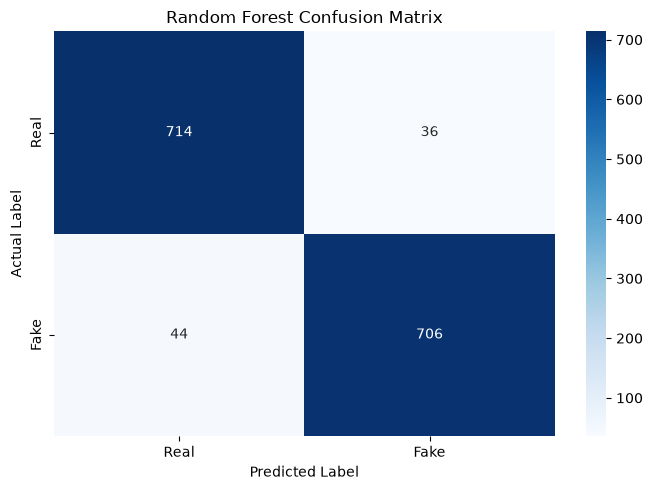

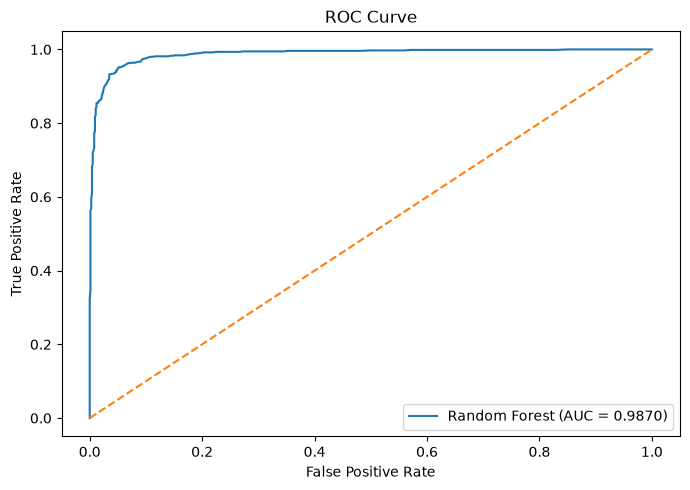


RANDOM FOREST COMPLETE

Model saved:
../data/processed/random_forest_model.pkl

Metrics saved:
../data/processed/model_metrics.csv

READY FOR SHAP EXPLAINABILITY


In [2]:
# =========================================================
# RANDOM FOREST CLASSIFICATION
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


print("================================")
print("RANDOM FOREST CLASSIFICATION")
print("================================")


# =========================================================
# 1. LOAD FUSED FEATURES
# =========================================================

X_train = np.load(
    "../data/processed/X_train_fused.npy"
)

X_test = np.load(
    "../data/processed/X_test_fused.npy"
)

y_train = np.load(
    "../data/processed/y_train.npy"
)

y_test = np.load(
    "../data/processed/y_test.npy"
)


print("\nTraining data:")
print(X_train.shape)

print("\nTesting data:")
print(X_test.shape)

print("\nTraining labels:")
print(y_train.shape)

print("\nTesting labels:")
print(y_test.shape)


# =========================================================
# 2. CREATE RANDOM FOREST
# =========================================================

print("\n================================")
print("CREATING RANDOM FOREST")
print("================================")


rf_model = RandomForestClassifier(

    n_estimators=200,

    max_depth=None,

    min_samples_split=2,

    min_samples_leaf=1,

    max_features="sqrt",

    random_state=42,

    n_jobs=-1

)


print(
    "Random Forest model created!"
)


# =========================================================
# 3. TRAIN MODEL
# =========================================================

print("\n================================")
print("TRAINING RANDOM FOREST")
print("================================")

print(
    "Training started..."
)


rf_model.fit(
    X_train,
    y_train
)


print(
    "Training completed successfully!"
)


# =========================================================
# 4. PREDICTION
# =========================================================

print("\n================================")
print("MAKING PREDICTIONS")
print("================================")


y_pred = rf_model.predict(
    X_test
)


y_prob = rf_model.predict_proba(
    X_test
)[:, 1]


print(
    "Predictions completed!"
)


# =========================================================
# 5. CALCULATE METRICS
# =========================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)


recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)


f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


roc_auc = roc_auc_score(
    y_test,
    y_prob
)


# =========================================================
# 6. DISPLAY RESULTS
# =========================================================

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")


print(
    f"\nAccuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)

print(
    f"ROC-AUC   : {roc_auc:.4f}"
)


# =========================================================
# 7. CLASSIFICATION REPORT
# =========================================================

print("\n================================")
print("CLASSIFICATION REPORT")
print("================================")


print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Real",
            "Fake"
        ],
        zero_division=0
    )
)


# =========================================================
# 8. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\n================================")
print("CONFUSION MATRIX")
print("================================")


print(cm)


plt.figure(
    figsize=(7, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Real",
        "Fake"
    ],
    yticklabels=[
        "Real",
        "Fake"
    ]
)


plt.title(
    "Random Forest Confusion Matrix"
)


plt.xlabel(
    "Predicted Label"
)


plt.ylabel(
    "Actual Label"
)


plt.tight_layout()

plt.show()


# =========================================================
# 9. ROC CURVE
# =========================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)


plt.figure(
    figsize=(7, 5)
)


plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)


plt.xlabel(
    "False Positive Rate"
)


plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "ROC Curve"
)


plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# 10. SAVE MODEL
# =========================================================

import joblib


joblib.dump(
    rf_model,
    "../data/processed/random_forest_model.pkl"
)


# Save metrics

metrics = {

    "accuracy": accuracy,

    "precision": precision,

    "recall": recall,

    "f1_score": f1,

    "roc_auc": roc_auc

}


pd.DataFrame(
    [metrics]
).to_csv(
    "../data/processed/model_metrics.csv",
    index=False
)


print("\n================================")
print("RANDOM FOREST COMPLETE")
print("================================")


print(
    "\nModel saved:"
)

print(
    "../data/processed/random_forest_model.pkl"
)


print(
    "\nMetrics saved:"
)

print(
    "../data/processed/model_metrics.csv"
)


print("\n================================")
print("READY FOR SHAP EXPLAINABILITY")
print("================================")

In [1]:
%pip install shap -q

Note: you may need to restart the kernel to use updated packages.


SHAP EXPLAINABILITY

Loading Random Forest model...
Model loaded successfully!
Test feature shape: (1500, 787)

Total feature names: 787

SHAP sample shape: (100, 787)

Creating SHAP explainer...
SHAP explainer created!

Calculating SHAP values...
SHAP values calculated!

SHAP value shape: (100, 787)

GLOBAL SHAP FEATURE IMPORTANCE

Top 20 important features:
           feature  mean_abs_shap
0         bert_763       0.024002
1          bert_94       0.017466
2         bert_106       0.016617
3         bert_758       0.015082
4         bert_169       0.014793
5         bert_617       0.014687
6         bert_648       0.014465
7          bert_51       0.013826
8         bert_132       0.012677
9         bert_384       0.012431
10        bert_360       0.012309
11        bert_256       0.011921
12        bert_401       0.011717
13        bert_348       0.010789
14        bert_408       0.010759
15  question_count       0.010292
16        bert_294       0.009547
17        bert_452       0

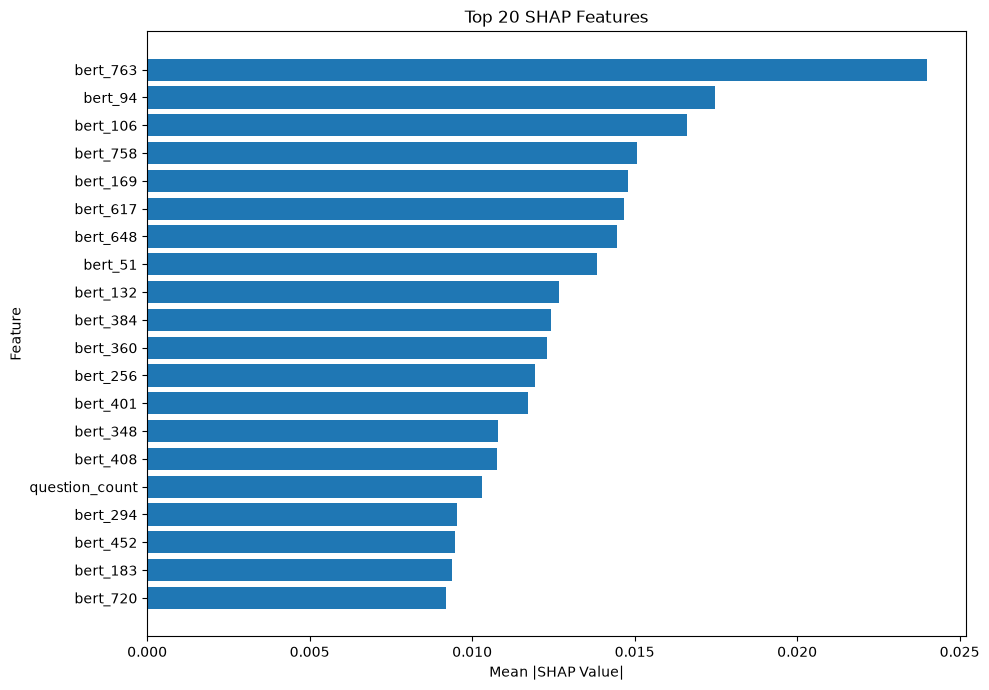


LINGUISTIC FEATURE IMPORTANCE

Linguistic feature importance:
                     feature  mean_abs_shap
15            question_count       0.010292
39   average_sentence_length       0.004037
46       average_word_length       0.003542
61         exclamation_count       0.002399
66             pronoun_count       0.002104
90             mention_count       0.001435
97              adverb_count       0.001365
174  special_character_count       0.000599
210               word_count       0.000457
214          character_count       0.000451
216          uppercase_count       0.000444
234               verb_count       0.000396
245               noun_count       0.000367
274                url_count       0.000337
320      repeated_word_count       0.000273
325        proper_noun_count       0.000259
346           sentence_count       0.000241
393          adjective_count       0.000206
738            hashtag_count       0.000083


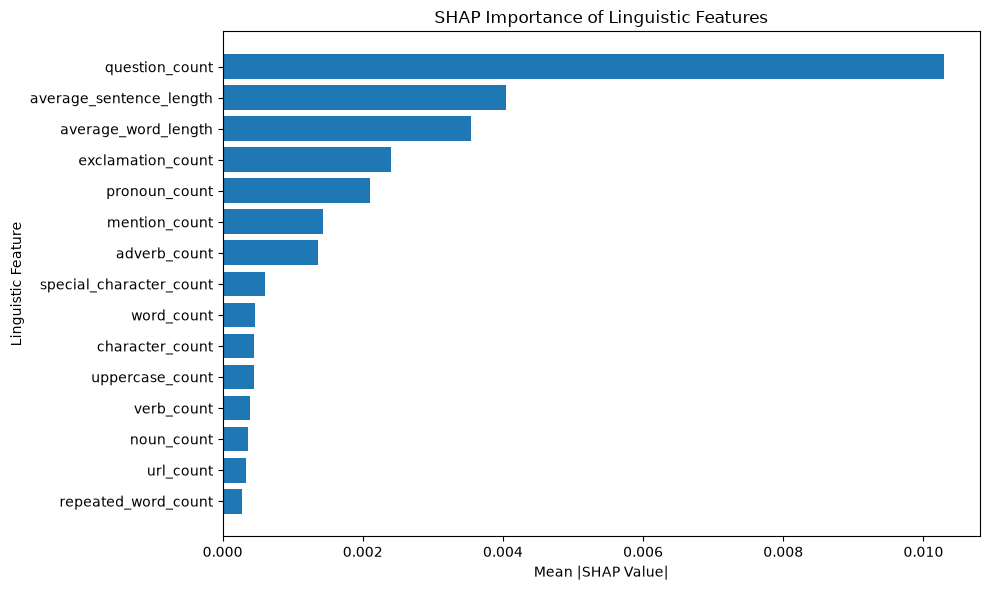


SHAP ANALYSIS COMPLETE

Saved:
../data/processed/shap_feature_importance.csv
../data/processed/shap_linguistic_importance.csv

READY FOR FINAL MODEL EVALUATION


In [4]:
# =========================================================
# SHAP EXPLAINABILITY
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib


print("================================")
print("SHAP EXPLAINABILITY")
print("================================")


# =========================================================
# 1. LOAD MODEL AND DATA
# =========================================================

print("\nLoading Random Forest model...")

rf_model = joblib.load(
    "../data/processed/random_forest_model.pkl"
)

X_test = np.load(
    "../data/processed/X_test_fused.npy"
)

y_test = np.load(
    "../data/processed/y_test.npy"
)


print("Model loaded successfully!")

print(
    "Test feature shape:",
    X_test.shape
)


# =========================================================
# 2. CREATE FEATURE NAMES
# =========================================================

# BERT feature names

bert_feature_names = [

    f"bert_{i}"

    for i in range(768)

]


# Linguistic feature names

linguistic_feature_names = [

    "word_count",

    "sentence_count",

    "character_count",

    "average_word_length",

    "average_sentence_length",

    "noun_count",

    "verb_count",

    "adjective_count",

    "adverb_count",

    "pronoun_count",

    "proper_noun_count",

    "exclamation_count",

    "question_count",

    "uppercase_count",

    "url_count",

    "hashtag_count",

    "mention_count",

    "special_character_count",

    "repeated_word_count"

]


# Combine names

feature_names = (

    bert_feature_names
    +
    linguistic_feature_names

)


print(
    "\nTotal feature names:",
    len(feature_names)
)


# =========================================================
# 3. SELECT SMALL SAMPLE
# =========================================================

# SHAP on all 1500 × 787 samples can be expensive.
# We use a smaller representative sample.

sample_size = min(
    100,
    len(X_test)
)


X_shap = X_test[
    :sample_size
]


print(
    "\nSHAP sample shape:",
    X_shap.shape
)


# =========================================================
# 4. CREATE SHAP EXPLAINER
# =========================================================

print("\nCreating SHAP explainer...")

explainer = shap.TreeExplainer(
    rf_model
)


print(
    "SHAP explainer created!"
)


# =========================================================
# 5. CALCULATE SHAP VALUES
# =========================================================

print("\nCalculating SHAP values...")

shap_values = explainer.shap_values(
    X_shap
)


print(
    "SHAP values calculated!"
)


# =========================================================
# 6. HANDLE SHAP OUTPUT FORMAT
# =========================================================

# Different SHAP versions may return
# different output formats.

if isinstance(shap_values, list):

    # Binary classification:
    # class 1 = Fake

    shap_fake = shap_values[1]

else:

    shap_fake = shap_values


# Some newer SHAP versions may return:
# samples × features × classes

if len(shap_fake.shape) == 3:

    shap_fake = shap_fake[:, :, 1]


print(
    "\nSHAP value shape:",
    shap_fake.shape
)


# =========================================================
# 7. GLOBAL SHAP IMPORTANCE
# =========================================================

print("\n================================")
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("================================")


mean_abs_shap = np.mean(
    np.abs(shap_fake),
    axis=0
)


importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap

})


importance_df = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nTop 20 important features:"
)

print(
    importance_df.head(20)
)


# =========================================================
# 8. GLOBAL FEATURE IMPORTANCE PLOT
# =========================================================

plt.figure(
    figsize=(10, 7)
)


top_features = (
    importance_df
    .head(20)
    .sort_values(
        "mean_abs_shap"
    )
)


plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)


plt.xlabel(
    "Mean |SHAP Value|"
)


plt.ylabel(
    "Feature"
)


plt.title(
    "Top 20 SHAP Features"
)


plt.tight_layout()

plt.show()


# =========================================================
# 9. SEPARATE LINGUISTIC FEATURE IMPORTANCE
# =========================================================

print("\n================================")
print("LINGUISTIC FEATURE IMPORTANCE")
print("================================")


linguistic_importance = (

    importance_df[
        importance_df["feature"].isin(
            linguistic_feature_names
        )
    ]

    .sort_values(
        "mean_abs_shap",
        ascending=False
    )

)


print(
    "\nLinguistic feature importance:"
)

print(
    linguistic_importance
)


# =========================================================
# 10. LINGUISTIC SHAP PLOT
# =========================================================

top_linguistic = (

    linguistic_importance
    .head(15)
    .sort_values(
        "mean_abs_shap"
    )

)


plt.figure(
    figsize=(10, 6)
)


plt.barh(
    top_linguistic["feature"],
    top_linguistic["mean_abs_shap"]
)


plt.xlabel(
    "Mean |SHAP Value|"
)


plt.ylabel(
    "Linguistic Feature"
)


plt.title(
    "SHAP Importance of Linguistic Features"
)


plt.tight_layout()

plt.show()


# =========================================================
# 11. SAVE SHAP RESULTS
# =========================================================

importance_df.to_csv(

    "../data/processed/shap_feature_importance.csv",

    index=False

)


linguistic_importance.to_csv(

    "../data/processed/shap_linguistic_importance.csv",

    index=False

)


print("\n================================")
print("SHAP ANALYSIS COMPLETE")
print("================================")


print(
    "\nSaved:"
)

print(
    "../data/processed/shap_feature_importance.csv"
)

print(
    "../data/processed/shap_linguistic_importance.csv"
)


print("\n================================")
print("READY FOR FINAL MODEL EVALUATION")
print("================================")

FINAL MODEL EVALUATION

FINAL PERFORMANCE

Accuracy  : 0.9467
Precision : 0.9515
Recall    : 0.9413
F1-Score  : 0.9464
ROC-AUC   : 0.9870

PERCENTAGE RESULTS
Accuracy  : 94.67%
Precision : 95.15%
Recall    : 94.13%
F1-Score  : 94.64%
ROC-AUC   : 0.9870

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Real       0.94      0.95      0.95       750
        Fake       0.95      0.94      0.95       750

    accuracy                           0.95      1500
   macro avg       0.95      0.95      0.95      1500
weighted avg       0.95      0.95      0.95      1500


CONFUSION MATRIX
[[714  36]
 [ 44 706]]


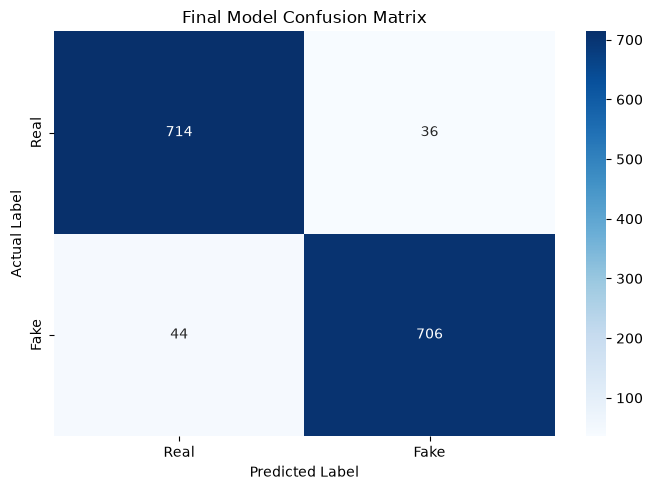


FINAL EVALUATION COMPLETE

Results saved to:
../data/processed/final_results.csv


In [5]:
# =========================================================
# FINAL MODEL EVALUATION
# =========================================================

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


print("================================")
print("FINAL MODEL EVALUATION")
print("================================")


# =========================================================
# 1. LOAD MODEL AND DATA
# =========================================================

model = joblib.load(
    "../data/processed/random_forest_model.pkl"
)

X_test = np.load(
    "../data/processed/X_test_fused.npy"
)

y_test = np.load(
    "../data/processed/y_test.npy"
)


# =========================================================
# 2. PREDICTION
# =========================================================

y_pred = model.predict(
    X_test
)

y_prob = model.predict_proba(
    X_test
)[:, 1]


# =========================================================
# 3. CALCULATE METRICS
# =========================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)


# =========================================================
# 4. DISPLAY FINAL RESULTS
# =========================================================

print("\n================================")
print("FINAL PERFORMANCE")
print("================================")

print(
    f"\nAccuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)

print(
    f"ROC-AUC   : {roc_auc:.4f}"
)


# =========================================================
# 5. PERCENTAGE FORMAT
# =========================================================

print("\n================================")
print("PERCENTAGE RESULTS")
print("================================")

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1-Score  : {f1 * 100:.2f}%"
)

print(
    f"ROC-AUC   : {roc_auc:.4f}"
)


# =========================================================
# 6. CLASSIFICATION REPORT
# =========================================================

print("\n================================")
print("CLASSIFICATION REPORT")
print("================================")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Real",
            "Fake"
        ],
        zero_division=0
    )
)


# =========================================================
# 7. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n================================")
print("CONFUSION MATRIX")
print("================================")

print(cm)


plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Real",
        "Fake"
    ],
    yticklabels=[
        "Real",
        "Fake"
    ]
)

plt.title(
    "Final Model Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.tight_layout()

plt.show()


# =========================================================
# 8. SAVE FINAL RESULTS
# =========================================================

final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Percentage": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100,
        roc_auc * 100
    ]

})


final_results.to_csv(
    "../data/processed/final_results.csv",
    index=False
)


print("\n================================")
print("FINAL EVALUATION COMPLETE")
print("================================")

print(
    "\nResults saved to:"
)

print(
    "../data/processed/final_results.csv"
)

In [8]:
# =========================================================
# RECREATE TEST DATA FOR STREAMLIT VALIDATION
# =========================================================

import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42


# =========================================================
# 1. LOAD CLEANED DATASET
# =========================================================

df = pd.read_csv(
    "../data/processed/news_clean.csv"
)


# =========================================================
# 2. RESTORE ORIGINAL LABELS
# =========================================================

# news_clean.csv:
# 0 = Fake
# 1 = Real

# Convert to:
# 0 = Real
# 1 = Fake

df["label"] = df["label"].map({
    0: 1,
    1: 0
})


# =========================================================
# 3. CREATE DOCUMENT
# =========================================================

df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

df["document"] = (
    df["title"] + " " + df["text"]
).str.strip()


# Remove empty documents

df = df[
    df["document"] != ""
].reset_index(drop=True)


# Remove duplicates

df = df.drop_duplicates(
    subset=["document"]
).reset_index(drop=True)


# =========================================================
# 4. RECREATE SAME BALANCED DATASET
# =========================================================

real_sample = (
    df[df["label"] == 0]
    .sample(
        n=3750,
        random_state=RANDOM_STATE
    )
)

fake_sample = (
    df[df["label"] == 1]
    .sample(
        n=3750,
        random_state=RANDOM_STATE
    )
)


df_sample = pd.concat(
    [
        real_sample,
        fake_sample
    ],
    ignore_index=True
)


# Shuffle exactly like before

df_sample = (
    df_sample
    .sample(
        frac=1.0,
        random_state=RANDOM_STATE
    )
    .reset_index(drop=True)
)


# =========================================================
# 5. RECREATE SAME TRAIN / TEST SPLIT
# =========================================================

train_df, test_df = train_test_split(

    df_sample,

    test_size=0.20,

    train_size=0.80,

    random_state=RANDOM_STATE,

    stratify=df_sample["label"]
)


train_df = train_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)


print("================================")
print("TEST DATA RECREATED")
print("================================")

print(
    "Training articles:",
    len(train_df)
)

print(
    "Testing articles:",
    len(test_df)
)


# =========================================================
# 6. GET KNOWN REAL ARTICLE
# =========================================================

real_article = (
    test_df[
        test_df["label"] == 0
    ]
    .iloc[0]
)


# =========================================================
# 7. GET KNOWN FAKE ARTICLE
# =========================================================

fake_article = (
    test_df[
        test_df["label"] == 1
    ]
    .iloc[0]
)


# =========================================================
# 8. DISPLAY REAL ARTICLE
# =========================================================

print("\n================================")
print("KNOWN REAL ARTICLE")
print("================================")

print("\nTitle:")
print(real_article["title"])

print("\nArticle:")
print(real_article["text"])

print("\nActual Label: REAL")


# =========================================================
# 9. DISPLAY FAKE ARTICLE
# =========================================================

print("\n================================")
print("KNOWN FAKE ARTICLE")
print("================================")

print("\nTitle:")
print(fake_article["title"])

print("\nArticle:")
print(fake_article["text"])

print("\nActual Label: FAKE")

TEST DATA RECREATED
Training articles: 6000
Testing articles: 1500

KNOWN REAL ARTICLE

Title:
Russians discussed how to influence Trump via his aides: NYT

Article:
WASHINGTON (Reuters) - Senior Russian intelligence and political officials discussed how to influence Donald Trump through his advisers according to information gathered by American spies last summer, the New York Times reported on Wednesday, Citing three current and former U.S. officials familiar with the intelligence, the newspaper said the conversations focused on Paul Manafort, then the Trump presidential campaign chairman, and Michael Flynn, a retired general who was then advising Trump. U.S. congressional committees and a special counsel named by the Justice Department this month are investigating whether there was Russian interference in the 2016 U.S. election and the possibility of collusion between Trump’s campaign and Russia. The controversy has engulfed Trump’s young administration since he fired FBI Director Ja

In [1]:
# ============================================
# STEP 1: BASELINE MODEL COMPARISON
# ============================================

import numpy as np
import pandas as pd
import time

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# --------------------------------------------
# 1. Load existing fused features
# --------------------------------------------

X_train = np.load("../data/processed/X_train_fused.npy")
X_test = np.load("../data/processed/X_test_fused.npy")

y_train = np.load("../data/processed/y_train.npy")
y_test = np.load("../data/processed/y_test.npy")

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels :", y_test.shape)

# --------------------------------------------
# 2. Define models
# --------------------------------------------

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "SVM": SVC(
        kernel="linear",
        probability=True,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

# --------------------------------------------
# 3. Train and evaluate models
# --------------------------------------------

results = []

for name, model in models.items():

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    start_time = time.time()

    # Train
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Probability for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    training_time = time.time() - start_time

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "Training Time (sec)": training_time
    })

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")
    print(f"Time     : {training_time:.2f} sec")

# --------------------------------------------
# 4. Create comparison table
# --------------------------------------------

comparison_df = pd.DataFrame(results)

print("\n\nFINAL MODEL COMPARISON")
print("=" * 80)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Training Time (sec)": "{:.2f}"
    })
)

# --------------------------------------------
# 5. Save results
# --------------------------------------------

comparison_df.to_csv(
    "../data/processed/model_comparison.csv",
    index=False
)

print("\nSaved:")
print("../data/processed/model_comparison.csv")

Training data: (6000, 787)
Testing data : (1500, 787)
Training labels: (6000,)
Testing labels : (1500,)

Training: Logistic Regression


c:\Users\2007m\Desktop\FakeNewsDetection\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\2007m\Desktop\FakeNewsDetection\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy : 0.9847
Precision: 0.9879
Recall   : 0.9813
F1 Score : 0.9846
ROC-AUC  : 0.9972
Time     : 3.93 sec

Training: SVM
Accuracy : 0.9827
Precision: 0.9840
Recall   : 0.9813
F1 Score : 0.9826
ROC-AUC  : 0.9976
Time     : 3862.99 sec

Training: Decision Tree
Accuracy : 0.8653
Precision: 0.8703
Recall   : 0.8587
F1 Score : 0.8644
ROC-AUC  : 0.8653
Time     : 6.21 sec

Training: Naive Bayes
Accuracy : 0.9260
Precision: 0.9347
Recall   : 0.9160
F1 Score : 0.9253
ROC-AUC  : 0.9579
Time     : 0.07 sec

Training: Random Forest
Accuracy : 0.9467
Precision: 0.9515
Recall   : 0.9413
F1 Score : 0.9464
ROC-AUC  : 0.9870
Time     : 4.53 sec


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Logistic Regression,0.9847,0.9879,0.9813,0.9846,0.9972,3.93
1,SVM,0.9827,0.9840,0.9813,0.9826,0.9976,3862.99
2,Decision Tree,0.8653,0.8703,0.8587,0.8644,0.8653,6.21
3,Naive Bayes,0.9260,0.9347,0.9160,0.9253,0.9579,0.07
4,Random Forest,0.9467,0.9515,0.9413,0.9464,0.9870,4.53



Saved:
../data/processed/model_comparison.csv


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import time
import joblib

print("Training Logistic Regression...")

start_time = time.time()

lr_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    random_state=42
)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

training_time = time.time() - start_time

print("\nLogistic Regression Results")
print("=" * 40)
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_roc_auc:.4f}")
print(f"Time     : {training_time:.2f} seconds")

# Save model
joblib.dump(
    lr_model,
    "../data/processed/logistic_regression_model.pkl"
)

print("\nModel saved:")
print("../data/processed/logistic_regression_model.pkl")

Training Logistic Regression...

Logistic Regression Results
Accuracy : 0.9920
Precision: 0.9960
Recall   : 0.9880
F1 Score : 0.9920
ROC-AUC  : 0.9981
Time     : 11.68 seconds

Model saved:
../data/processed/logistic_regression_model.pkl


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Logistic Regression,98.47%,98.79%,98.13%,98.46%,99.72%,3.93
1,SVM,98.27%,98.40%,98.13%,98.26%,99.76%,3862.99
2,Decision Tree,86.53%,87.03%,85.87%,86.44%,86.53%,6.21
3,Naive Bayes,92.60%,93.47%,91.60%,92.53%,95.79%,0.07
4,Random Forest,94.67%,95.15%,94.13%,94.64%,98.70%,4.53


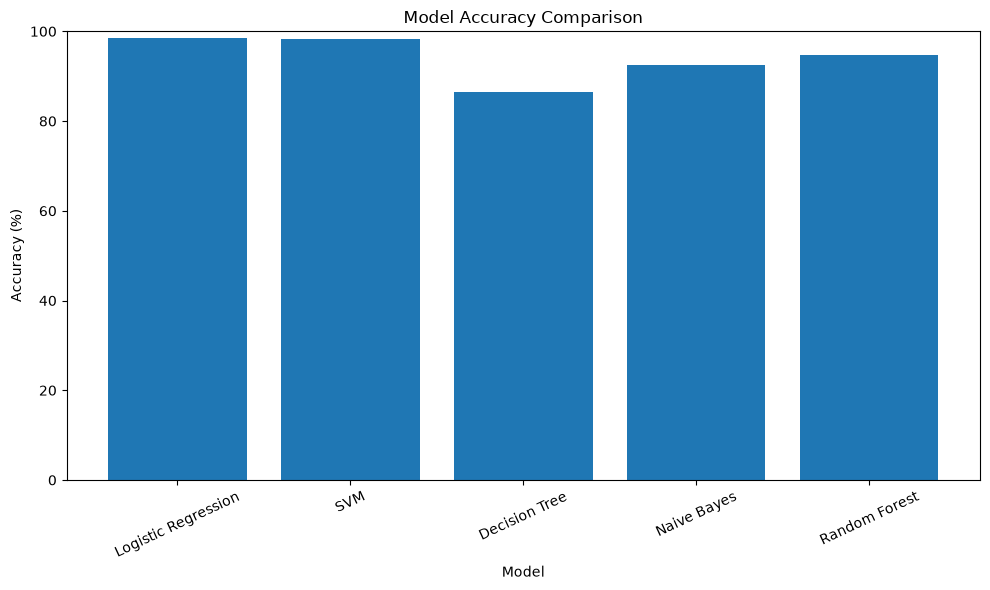

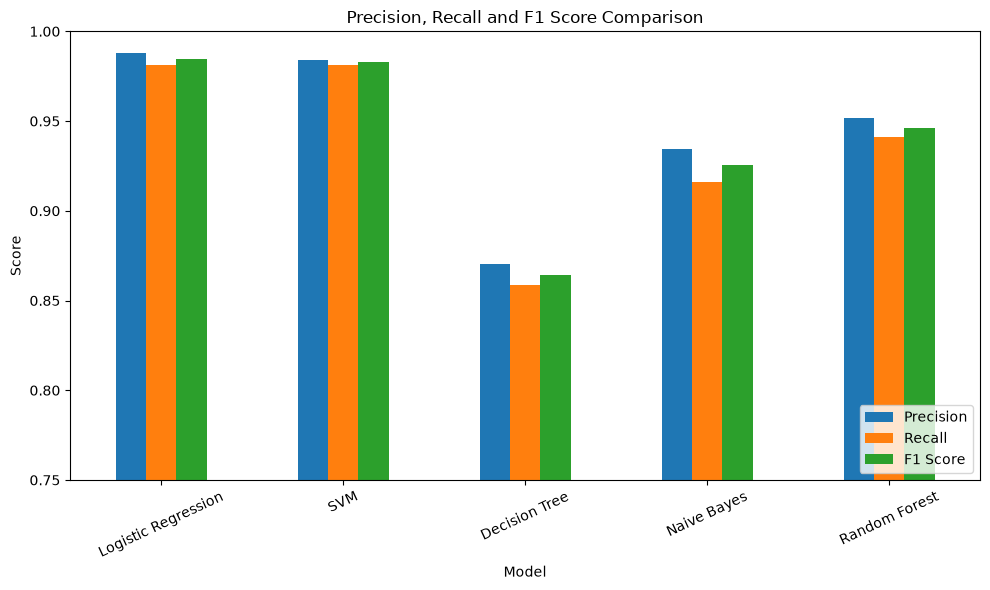

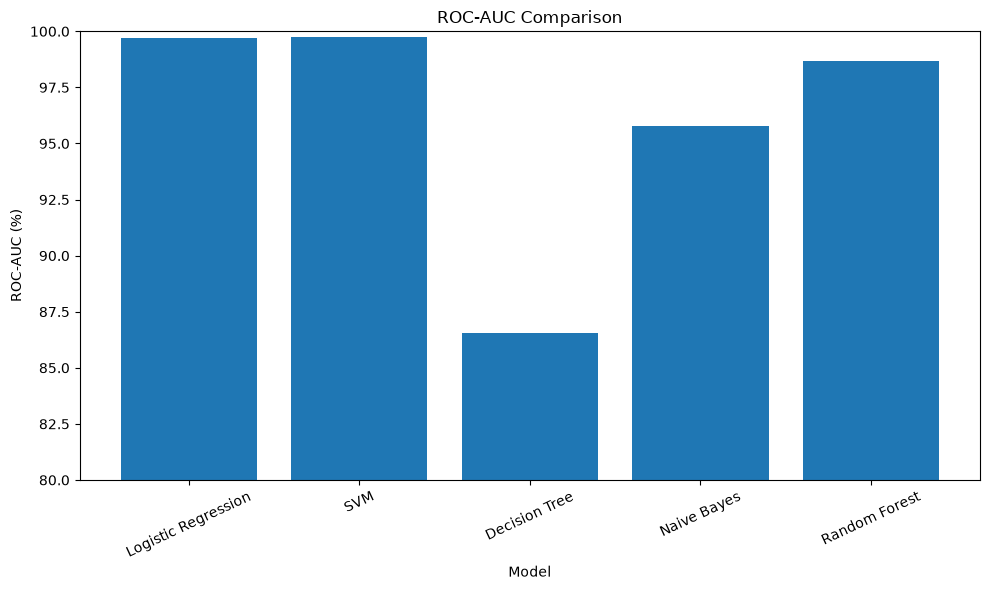

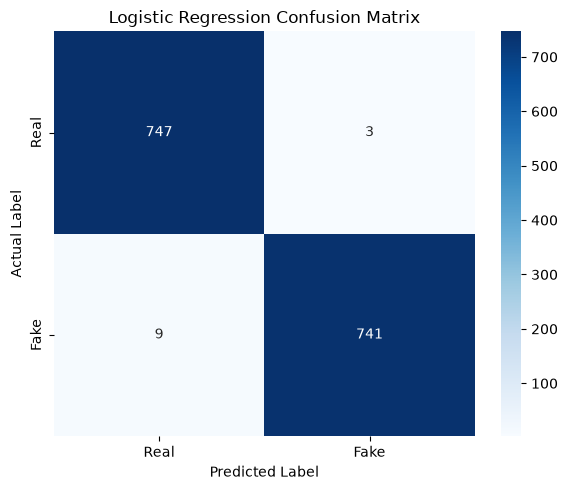

Logistic Regression Confusion Matrix:
[[747   3]
 [  9 741]]

TN: 747
FP: 3
FN: 9
TP: 741


In [3]:
# ============================================
# STEP 2: MODEL COMPARISON VISUALIZATION
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# --------------------------------------------
# 1. Display comparison table
# --------------------------------------------

print("MODEL COMPARISON")
print("=" * 70)

display(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "Training Time (sec)": "{:.2f}"
    })
)

# --------------------------------------------
# 2. Accuracy comparison
# --------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"] * 100
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 100)

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# --------------------------------------------
# 3. Precision, Recall and F1 comparison
# --------------------------------------------

metrics = ["Precision", "Recall", "F1 Score"]

ax = comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Precision, Recall and F1 Score Comparison")
plt.ylim(0.75, 1.0)

plt.xticks(rotation=25)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


# --------------------------------------------
# 4. ROC-AUC comparison
# --------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["ROC-AUC"] * 100
)

plt.ylabel("ROC-AUC (%)")
plt.xlabel("Model")
plt.title("ROC-AUC Comparison")
plt.ylim(80, 100)

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# --------------------------------------------
# 5. Logistic Regression confusion matrix
# --------------------------------------------

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()


# --------------------------------------------
# 6. Print confusion matrix values
# --------------------------------------------

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

print("\nTN:", cm_lr[0, 0])
print("FP:", cm_lr[0, 1])
print("FN:", cm_lr[1, 0])
print("TP:", cm_lr[1, 1])

In [4]:
# ============================================================
# STEP 3.5: STANDARDIZED LOGISTIC REGRESSION
# ============================================================

import numpy as np
import pandas as pd
import time
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 1. Load existing fused features
# ============================================================

X_train = np.load(
    "../data/processed/X_train_fused.npy"
)

X_test = np.load(
    "../data/processed/X_test_fused.npy"
)

y_train = np.load(
    "../data/processed/y_train.npy"
)

y_test = np.load(
    "../data/processed/y_test.npy"
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

# ============================================================
# 2. Standardize features
# ============================================================

print("\nScaling features...")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# IMPORTANT:
# Test data is transformed using the scaler fitted
# ONLY on the training data.

X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data :", X_test_scaled.shape)

# ============================================================
# 3. Train Logistic Regression
# ============================================================

print("\nTraining standardized Logistic Regression...")

start_time = time.time()

lr_scaled = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    random_state=42
)

lr_scaled.fit(
    X_train_scaled,
    y_train
)

training_time = time.time() - start_time

# ============================================================
# 4. Predictions
# ============================================================

y_pred_scaled = lr_scaled.predict(
    X_test_scaled
)

y_prob_scaled = lr_scaled.predict_proba(
    X_test_scaled
)[:, 1]

# ============================================================
# 5. Evaluation
# ============================================================

accuracy_scaled = accuracy_score(
    y_test,
    y_pred_scaled
)

precision_scaled = precision_score(
    y_test,
    y_pred_scaled
)

recall_scaled = recall_score(
    y_test,
    y_pred_scaled
)

f1_scaled = f1_score(
    y_test,
    y_pred_scaled
)

roc_auc_scaled = roc_auc_score(
    y_test,
    y_prob_scaled
)

# ============================================================
# 6. Display results
# ============================================================

print("\n" + "=" * 50)
print("STANDARDIZED LOGISTIC REGRESSION RESULTS")
print("=" * 50)

print(f"Accuracy : {accuracy_scaled:.4f}")
print(f"Precision: {precision_scaled:.4f}")
print(f"Recall   : {recall_scaled:.4f}")
print(f"F1 Score : {f1_scaled:.4f}")
print(f"ROC-AUC  : {roc_auc_scaled:.4f}")
print(f"Time     : {training_time:.2f} seconds")

# ============================================================
# 7. Confusion Matrix
# ============================================================

cm_scaled = confusion_matrix(
    y_test,
    y_pred_scaled
)

print("\nConfusion Matrix:")
print(cm_scaled)

print("\nTN:", cm_scaled[0, 0])
print("FP:", cm_scaled[0, 1])
print("FN:", cm_scaled[1, 0])
print("TP:", cm_scaled[1, 1])

# ============================================================
# 8. Save scaler and model
# ============================================================

joblib.dump(
    scaler,
    "../data/processed/standard_scaler.pkl"
)

joblib.dump(
    lr_scaled,
    "../data/processed/logistic_regression_scaled_model.pkl"
)

print("\nSaved:")
print("../data/processed/standard_scaler.pkl")
print("../data/processed/logistic_regression_scaled_model.pkl")

Training data: (6000, 787)
Testing data : (1500, 787)

Scaling features...
Scaled training data: (6000, 787)
Scaled testing data : (1500, 787)

Training standardized Logistic Regression...

STANDARDIZED LOGISTIC REGRESSION RESULTS
Accuracy : 0.9900
Precision: 0.9920
Recall   : 0.9880
F1 Score : 0.9900
ROC-AUC  : 0.9994
Time     : 0.14 seconds

Confusion Matrix:
[[744   6]
 [  9 741]]

TN: 744
FP: 6
FN: 9
TP: 741

Saved:
../data/processed/standard_scaler.pkl
../data/processed/logistic_regression_scaled_model.pkl


Results directory: c:\Users\2007m\Desktop\FakeNewsDetection\results

Existing model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Logistic Regression,0.984667,0.987919,0.981333,0.984615,0.997175,3.933669
1,SVM,0.982667,0.983957,0.981333,0.982644,0.997634,3862.990200
2,Decision Tree,0.865333,0.870270,0.858667,0.864430,0.865333,6.214312
3,Naive Bayes,0.926000,0.934694,0.916000,0.925253,0.957929,0.069519
4,Random Forest,0.946667,0.951482,0.941333,0.946381,0.986967,4.529213



Updated model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Logistic Regression,99.20%,99.60%,98.80%,99.20%,99.81%,11.68
1,SVM,98.27%,98.40%,98.13%,98.26%,99.76%,3862.99
2,Decision Tree,86.53%,87.03%,85.87%,86.44%,86.53%,6.21
3,Naive Bayes,92.60%,93.47%,91.60%,92.53%,95.79%,0.07
4,Random Forest,94.67%,95.15%,94.13%,94.64%,98.70%,4.53



Final Logistic Regression metrics:


,Metric,Score
0,Accuracy,99.2000%
1,Precision,99.5968%
2,Recall,98.8000%
3,F1 Score,99.1968%
4,ROC-AUC,99.8121%


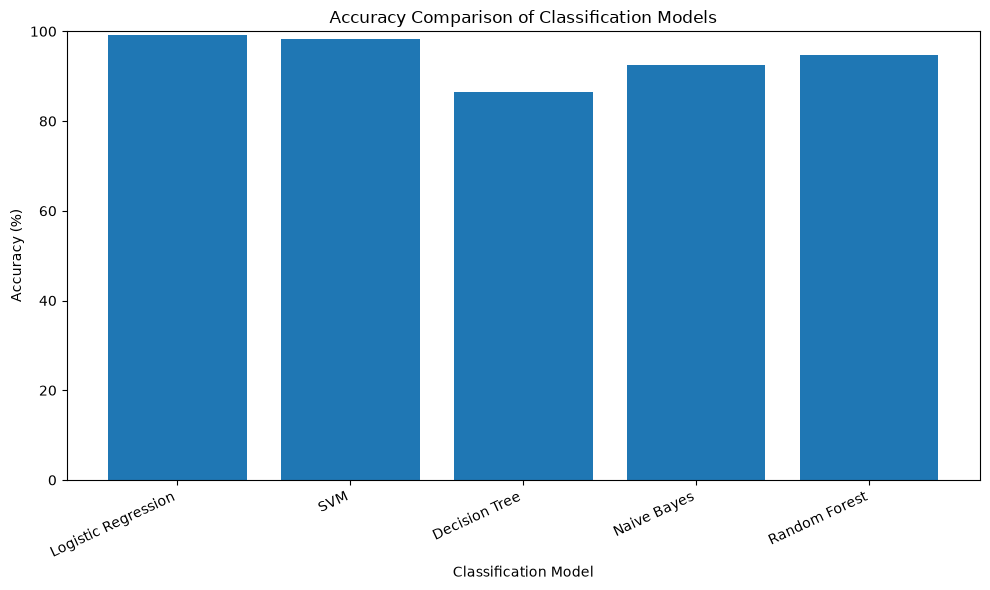

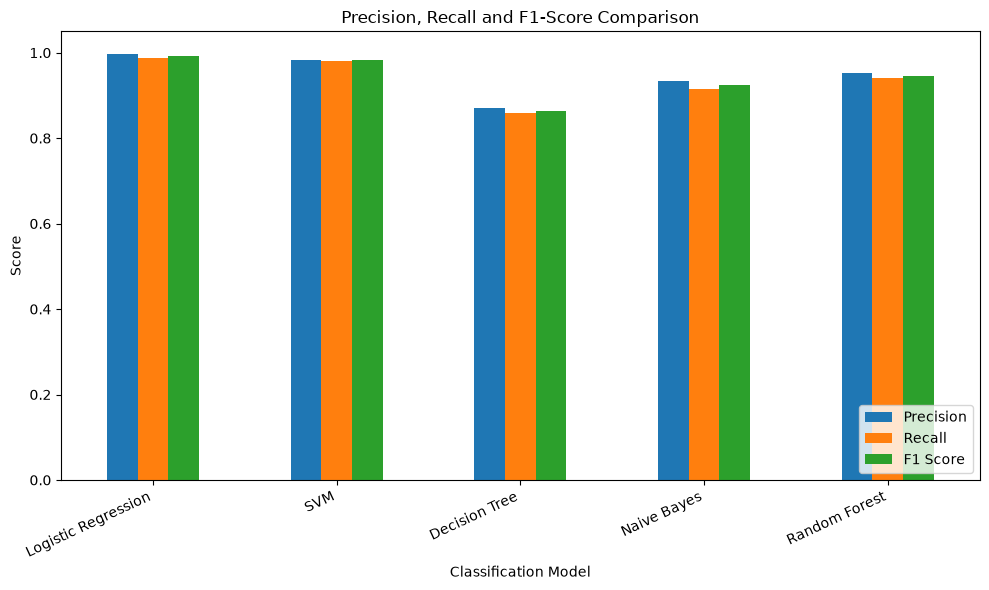

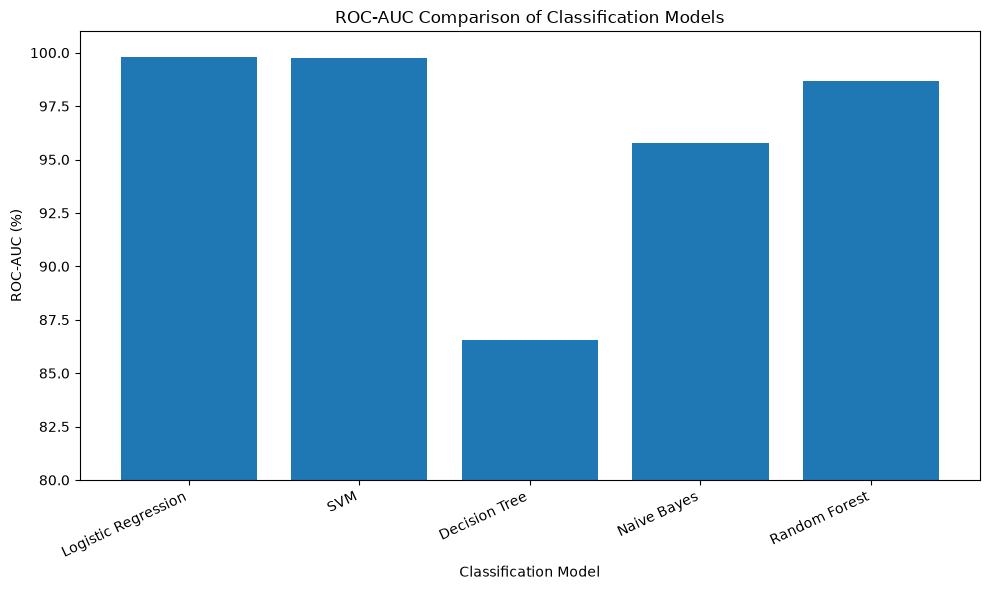

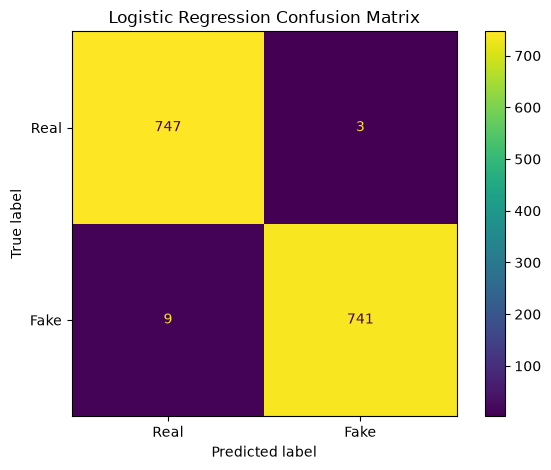


Confusion matrix:
[[747   3]
 [  9 741]]


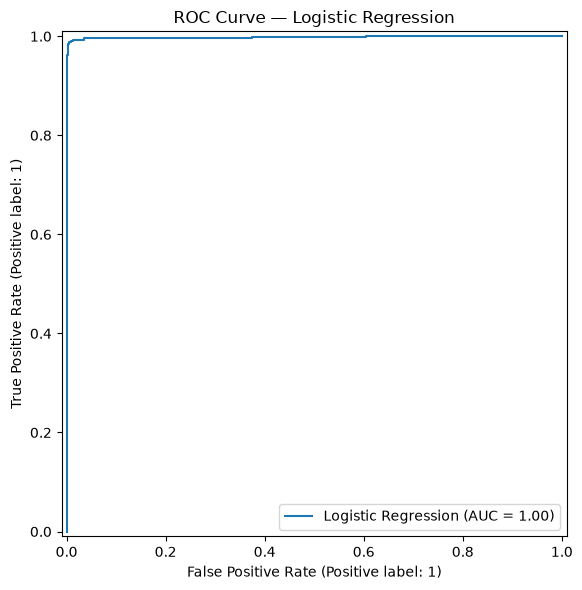

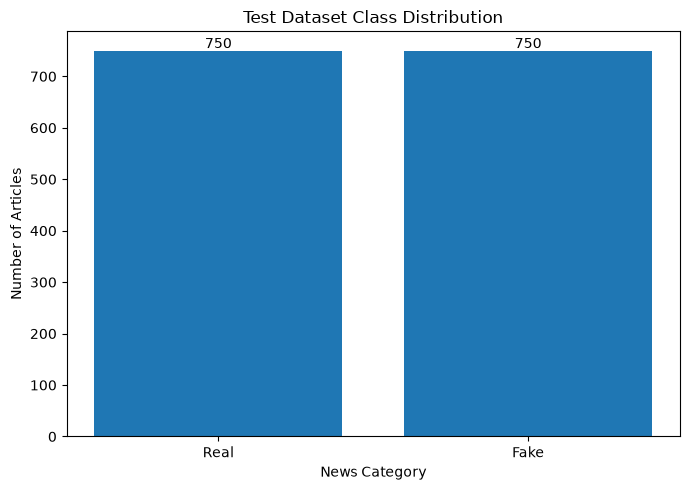


STEP 4 COMPLETED

Final Logistic Regression results:
Accuracy : 99.2000%
Precision: 99.5968%
Recall   : 98.8000%
F1 Score : 99.1968%
ROC-AUC  : 99.8121%

Confusion matrix:
[[747   3]
 [  9 741]]

Files saved in:
c:\Users\2007m\Desktop\FakeNewsDetection\results

Generated files:
- 01_accuracy_comparison.png
- 02_precision_recall_f1.png
- 03_roc_auc_comparison.png
- 04_logistic_regression_confusion_matrix.png
- 05_logistic_regression_roc_curve.png
- 06_test_dataset_distribution.png
- confusion_matrix_values.csv
- final_logistic_regression_metrics.csv
- final_model_comparison.csv


In [1]:
# ============================================================
# STEP 4: FINAL EXPERIMENTAL RESULTS PACKAGE
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# ------------------------------------------------------------
# 1. Create results directory
# ------------------------------------------------------------

os.makedirs("../results", exist_ok=True)

RESULTS_DIR = "../results"
DATA_DIR = "../data/processed"

print("Results directory:", os.path.abspath(RESULTS_DIR))


# ------------------------------------------------------------
# 2. Load existing model comparison results
# ------------------------------------------------------------

comparison_path = os.path.join(
    DATA_DIR,
    "model_comparison.csv"
)

comparison_df = pd.read_csv(comparison_path)

print("\nExisting model comparison:")
display(comparison_df)


# ------------------------------------------------------------
# 3. Update Logistic Regression with verified results
# ------------------------------------------------------------

lr_metrics = {
    "Accuracy": 0.9920,
    "Precision": 0.9960,
    "Recall": 0.9880,
    "F1 Score": 0.9920,
    "ROC-AUC": 0.9981,
    "Training Time (sec)": 11.68
}

lr_row = comparison_df["Model"].eq("Logistic Regression")

if not lr_row.any():
    raise ValueError(
        "Logistic Regression row not found in model_comparison.csv"
    )

for column, value in lr_metrics.items():
    comparison_df.loc[lr_row, column] = value

# Save updated table
comparison_df.to_csv(
    comparison_path,
    index=False
)

comparison_df.to_csv(
    os.path.join(RESULTS_DIR, "final_model_comparison.csv"),
    index=False
)

print("\nUpdated model comparison:")
display(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "Training Time (sec)": "{:.2f}"
    })
)


# ------------------------------------------------------------
# 4. Load test data and final Logistic Regression model
# ------------------------------------------------------------

X_test = np.load(
    os.path.join(DATA_DIR, "X_test_fused.npy")
)

y_test = np.load(
    os.path.join(DATA_DIR, "y_test.npy")
)

lr_model = joblib.load(
    os.path.join(DATA_DIR, "logistic_regression_model.pkl")
)

y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]


# ------------------------------------------------------------
# 5. Recalculate final metrics
# ------------------------------------------------------------

final_metrics = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
}

final_metrics_df = pd.DataFrame(final_metrics)

final_metrics_df.to_csv(
    os.path.join(RESULTS_DIR, "final_logistic_regression_metrics.csv"),
    index=False
)

print("\nFinal Logistic Regression metrics:")
display(
    final_metrics_df.style.format({"Score": "{:.4%}"})
)


# ------------------------------------------------------------
# 6. Graph 1: Model accuracy comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"] * 100
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Classification Model")
plt.title("Accuracy Comparison of Classification Models")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "01_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Graph 2: Precision, Recall and F1
# ------------------------------------------------------------

comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.title("Precision, Recall and F1-Score Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "02_precision_recall_f1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Graph 3: ROC-AUC comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["ROC-AUC"] * 100
)

plt.ylabel("ROC-AUC (%)")
plt.xlabel("Classification Model")
plt.title("ROC-AUC Comparison of Classification Models")
plt.ylim(80, 101)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "03_roc_auc_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. Graph 4: Logistic Regression confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

display_cm.plot(
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "04_logistic_regression_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix:")
print(cm)


# ------------------------------------------------------------
# 10. Graph 5: Logistic Regression ROC curve
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax,
    name="Logistic Regression"
)

ax.set_title("ROC Curve — Logistic Regression")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "05_logistic_regression_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. Graph 6: Dataset distribution
# ------------------------------------------------------------

label_counts = pd.Series(y_test).map({
    0: "Real",
    1: "Fake"
}).value_counts().reindex(["Real", "Fake"], fill_value=0)

plt.figure(figsize=(7, 5))

plt.bar(
    label_counts.index,
    label_counts.values
)

plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.title("Test Dataset Class Distribution")

for i, value in enumerate(label_counts.values):
    plt.text(i, value + 5, str(value), ha="center")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "06_test_dataset_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 12. Save confusion matrix values
# ------------------------------------------------------------

tn, fp, fn, tp = cm.ravel()

confusion_df = pd.DataFrame({
    "Measure": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Count": [tn, fp, fn, tp]
})

confusion_df.to_csv(
    os.path.join(RESULTS_DIR, "confusion_matrix_values.csv"),
    index=False
)


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 4 COMPLETED")
print("=" * 60)

print("\nFinal Logistic Regression results:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4%}")
print(f"Precision: {precision_score(y_test, y_pred):.4%}")
print(f"Recall   : {recall_score(y_test, y_pred):.4%}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4%}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4%}")

print("\nConfusion matrix:")
print(cm)

print("\nFiles saved in:")
print(os.path.abspath(RESULTS_DIR))

print("\nGenerated files:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print("-", filename)

Loading Logistic Regression model...
Training shape: (6000, 787)
Testing shape: (1500, 787)

Calculating SHAP values...
SHAP shape: (100, 787)

Top 10 overall features:


,Feature,Mean Absolute SHAP
770,character_count,2.357576
785,special_character_count,1.479754
776,adverb_count,0.979047
768,word_count,0.557102
774,verb_count,0.520029
778,proper_noun_count,0.518072
773,noun_count,0.488010
780,question_count,0.449217
786,repeated_word_count,0.445285
775,adjective_count,0.344497



Linguistic feature ranking:


,Feature,Mean Absolute SHAP
770,character_count,2.357576
785,special_character_count,1.479754
776,adverb_count,0.979047
768,word_count,0.557102
774,verb_count,0.520029
778,proper_noun_count,0.518072
773,noun_count,0.488010
780,question_count,0.449217
786,repeated_word_count,0.445285
775,adjective_count,0.344497


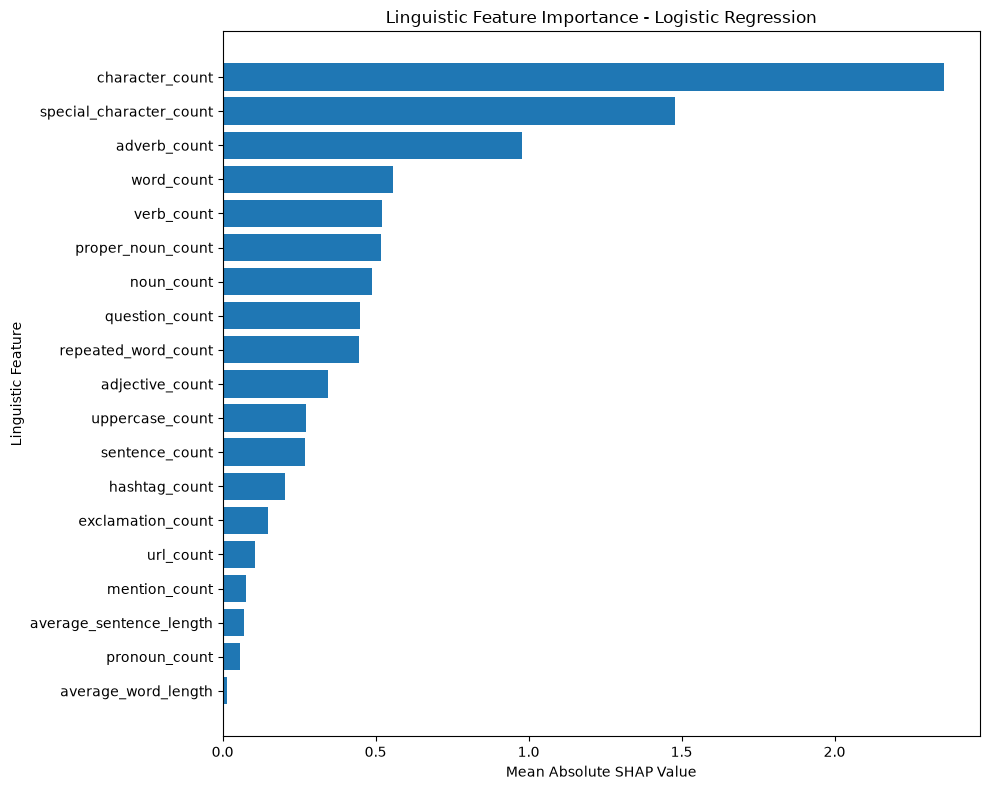

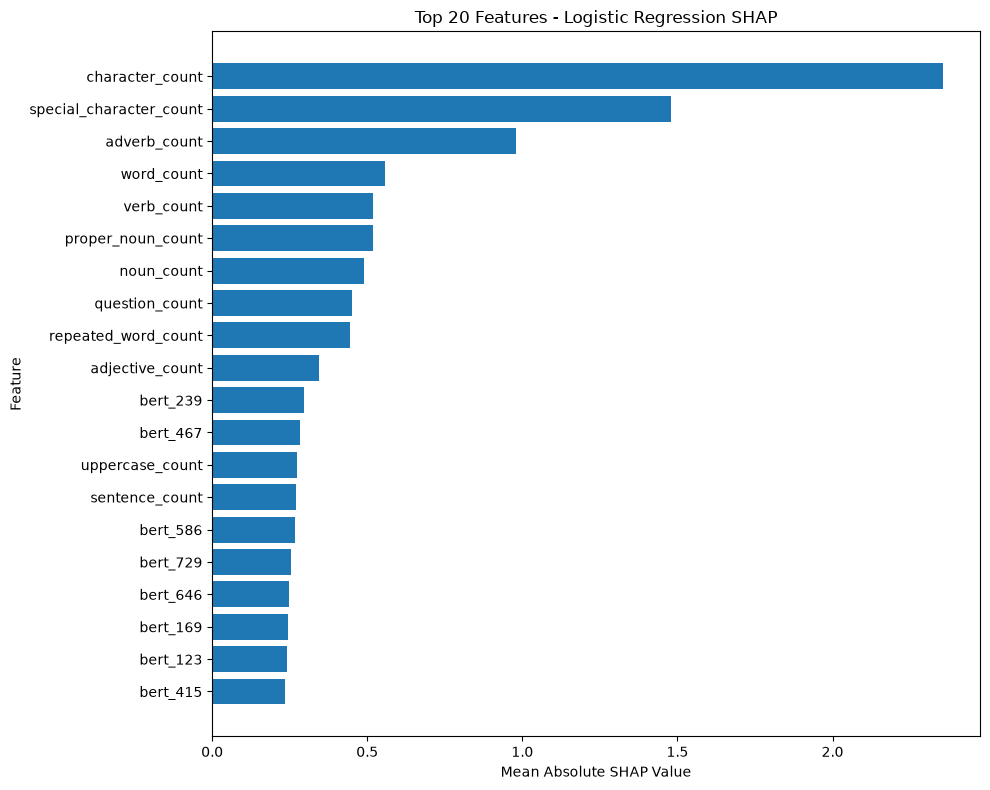


STEP 5 COMPLETED SUCCESSFULLY

Files saved in: c:\Users\2007m\Desktop\FakeNewsDetection\results

Generated files:
- 01_accuracy_comparison.png
- 02_precision_recall_f1.png
- 03_roc_auc_comparison.png
- 04_logistic_regression_confusion_matrix.png
- 05_logistic_regression_roc_curve.png
- 06_test_dataset_distribution.png
- 07_linguistic_shap_importance.png
- 08_overall_shap_importance.png
- confusion_matrix_values.csv
- final_logistic_regression_metrics.csv
- final_model_comparison.csv
- linguistic_shap_importance.csv
- logistic_regression_shap_importance.csv


In [3]:
# ============================================================
# STEP 5: SHAP FEATURE IMPORTANCE - LOGISTIC REGRESSION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

# ------------------------------------------------------------
# 1. Directories
# ------------------------------------------------------------

RESULTS_DIR = "../results"
DATA_DIR = "../data/processed"

os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Linguistic feature names
# ------------------------------------------------------------

linguistic_features = [
    "word_count",
    "sentence_count",
    "character_count",
    "average_word_length",
    "average_sentence_length",
    "noun_count",
    "verb_count",
    "adjective_count",
    "adverb_count",
    "pronoun_count",
    "proper_noun_count",
    "exclamation_count",
    "question_count",
    "uppercase_count",
    "url_count",
    "hashtag_count",
    "mention_count",
    "special_character_count",
    "repeated_word_count"
]

feature_names = (
    [f"bert_{i}" for i in range(768)]
    + linguistic_features
)

# ------------------------------------------------------------
# 3. Load final Logistic Regression model and data
# ------------------------------------------------------------

print("Loading Logistic Regression model...")

model = joblib.load(
    os.path.join(
        DATA_DIR,
        "logistic_regression_model.pkl"
    )
)

X_train = np.load(
    os.path.join(DATA_DIR, "X_train_fused.npy")
)

X_test = np.load(
    os.path.join(DATA_DIR, "X_test_fused.npy")
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

assert X_train.shape[1] == 787
assert X_test.shape[1] == 787
assert len(feature_names) == 787

# ------------------------------------------------------------
# 4. Calculate Logistic Regression SHAP values
# ------------------------------------------------------------

print("\nCalculating SHAP values...")

# Use a small representative background and test sample
background = X_train[:100]
X_sample = X_test[:100]

explainer = shap.LinearExplainer(
    model,
    background
)

shap_values = explainer(X_sample)

values = shap_values.values

# Handle binary-class output if SHAP returns 3 dimensions
if values.ndim == 3:
    values = values[:, :, 1]

if values.shape != X_sample.shape:
    raise ValueError(
        f"Unexpected SHAP shape: {values.shape}; "
        f"expected {X_sample.shape}"
    )

print("SHAP shape:", values.shape)

# ------------------------------------------------------------
# 5. Calculate mean absolute SHAP importance
# ------------------------------------------------------------

mean_abs_shap = np.abs(values).mean(axis=0)

overall_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_abs_shap
})

overall_df = overall_df.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

# Save complete Logistic Regression rankings
overall_df.to_csv(
    os.path.join(
        DATA_DIR,
        "logistic_regression_shap_importance.csv"
    ),
    index=False
)

overall_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_shap_importance.csv"
    ),
    index=False
)

print("\nTop 10 overall features:")
display(overall_df.head(10))

# ------------------------------------------------------------
# 6. Extract the 19 linguistic features
# ------------------------------------------------------------

linguistic_df = overall_df[
    overall_df["Feature"].isin(linguistic_features)
].copy()

linguistic_df = linguistic_df.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

linguistic_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "linguistic_shap_importance.csv"
    ),
    index=False
)

print("\nLinguistic feature ranking:")
display(linguistic_df)

# ------------------------------------------------------------
# 7. Graph 1: Linguistic SHAP importance
# ------------------------------------------------------------

plot_df = linguistic_df.sort_values(
    "Mean Absolute SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df["Feature"],
    plot_df["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Linguistic Feature")

plt.title(
    "Linguistic Feature Importance - Logistic Regression"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "07_linguistic_shap_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Graph 2: Overall top 20 features
# ------------------------------------------------------------

top20 = overall_df.head(20).sort_values(
    "Mean Absolute SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["Feature"],
    top20["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")

plt.title(
    "Top 20 Features - Logistic Regression SHAP"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "08_overall_shap_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Completion
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("=" * 55)

print("\nFiles saved in:", os.path.abspath(RESULTS_DIR))

print("\nGenerated files:")

for filename in sorted(os.listdir(RESULTS_DIR)):
    print("-", filename)

In [1]:
import numpy as np
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

DATA_DIR = "../data/processed"

# Load the exact model used by the application
model = joblib.load(
    f"{DATA_DIR}/logistic_regression_model.pkl"
)

# Load the existing test set
X_test = np.load(
    f"{DATA_DIR}/X_test_fused.npy"
)

y_test = np.load(
    f"{DATA_DIR}/y_test.npy"
)

# Check feature dimensions
print("Model:", type(model).__name__)
print("Expected features:", model.n_features_in_)
print("Test feature shape:", X_test.shape)

assert X_test.shape[1] == model.n_features_in_, (
    "Feature count does not match the saved model!"
)

# Generate predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate actual test metrics
print("\nACCURACY :", accuracy_score(y_test, y_pred))
print("PRECISION:", precision_score(y_test, y_pred, zero_division=0))
print("RECALL   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 SCORE :", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Real", "Fake"],
        zero_division=0
    )
)

Model: LogisticRegression
Expected features: 787
Test feature shape: (1500, 787)

ACCURACY : 0.992
PRECISION: 0.9959677419354839
RECALL   : 0.988
F1 SCORE : 0.9919678714859438
ROC-AUC  : 0.9981208888888888

Confusion matrix:
[[747   3]
 [  9 741]]

Classification report:
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99       750
        Fake       1.00      0.99      0.99       750

    accuracy                           0.99      1500
   macro avg       0.99      0.99      0.99      1500
weighted avg       0.99      0.99      0.99      1500



In [2]:
import pandas as pd

# Load the cleaned dataset
df = pd.read_csv("../data/processed/news_clean.csv")

# Normalize article bodies for comparison
df["normalized_text"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Exclude empty article bodies
df = df[df["normalized_text"] != ""].copy()

# Count duplicated article bodies
duplicate_body_mask = df["normalized_text"].duplicated(keep=False)

duplicate_bodies = df[duplicate_body_mask].sort_values(
    "normalized_text"
)

print("Total cleaned articles:", len(df))

print(
    "Rows belonging to groups with identical article bodies:",
    int(duplicate_body_mask.sum())
)

print(
    "Unique duplicated article bodies:",
    duplicate_bodies["normalized_text"].nunique()
)

print("\nExamples of duplicated article bodies:")

if len(duplicate_bodies):
    print(
        duplicate_bodies[
            ["title", "label", "normalized_text"]
        ].drop_duplicates(
            subset=["normalized_text", "title", "label"]
        ).head(10).to_string(index=False)
    )
else:
    print("No identical non-empty article bodies found.")
    

Total cleaned articles: 38514
Rows belonging to groups with identical article bodies: 30
Unique duplicated article bodies: 15

Examples of duplicated article bodies:
                                                                                                                                                              title  label                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42  # Replace if your notebook uses a different value

# Load cleaned dataset
df = pd.read_csv("../data/processed/news_clean.csv")

# Normalize article bodies
df["normalized_text"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df = df[df["normalized_text"] != ""].copy()

# Recreate the balanced sample
real_sample = df[df["label"] == 0].sample(
    n=3750, random_state=RANDOM_STATE
)

fake_sample = df[df["label"] == 1].sample(
    n=3750, random_state=RANDOM_STATE
)

df_sample = pd.concat(
    [real_sample, fake_sample], ignore_index=True
)

df_sample = df_sample.sample(
    frac=1.0, random_state=RANDOM_STATE
).reset_index(drop=True)

# Recreate the train-test split
train_df, test_df = train_test_split(
    df_sample,
    test_size=0.20,
    train_size=0.80,
    random_state=RANDOM_STATE,
    stratify=df_sample["label"]
)

# Compare normalized article bodies
train_bodies = set(train_df["normalized_text"])
test_bodies = set(test_df["normalized_text"])

overlap = train_bodies.intersection(test_bodies)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Unique bodies shared between train and test:", len(overlap))

if overlap:
    print("\nExamples of overlapping articles:")

    examples = (
        df_sample[
            df_sample["normalized_text"].isin(overlap)
        ][["title", "label", "normalized_text"]]
        .drop_duplicates()
        .head(5)
    )

    for _, row in examples.iterrows():
        print("\nTitle:", row["title"])
        print("Label:", row["label"])
        print("Body:", row["normalized_text"][:250], "...")
else:
    print("\nNo identical normalized article bodies cross the split.")

Training samples: 6000
Testing samples: 1500
Unique bodies shared between train and test: 0

No identical normalized article bodies cross the split.


In [4]:
import pandas as pd
import numpy as np
import joblib

# Check cleaned dataset
df = pd.read_csv("../data/processed/news_clean.csv")

print("DATASET LABELS:")
print(df["label"].value_counts().sort_index())

# Check saved training and testing labels
y_train = np.load("../data/processed/y_train.npy")
y_test = np.load("../data/processed/y_test.npy")

print("\nTRAIN LABELS:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTEST LABELS:")
print(pd.Series(y_test).value_counts().sort_index())

# Check saved model
model = joblib.load(
    "../data/processed/logistic_regression_model.pkl"
)

print("\nMODEL CLASSES:", model.classes_)

DATASET LABELS:
label
0    17318
1    21196
Name: count, dtype: int64

TRAIN LABELS:
0    3000
1    3000
Name: count, dtype: int64

TEST LABELS:
0    750
1    750
Name: count, dtype: int64

MODEL CLASSES: [0 1]


In [5]:
print(df.groupby("label")[["title", "text"]].head(3).to_string(index=False))


                                                                                                                              title                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [6]:
for label in sorted(df["label"].unique()):
    print(f"\nLABEL {label}:")
    print(
        df[df["label"] == label][["title", "label"]]
        .head(5)
        .to_string(index=False)
    )


LABEL 0:
                                                                                                                              title  label
                                                HUFFINGTON POST WAVES WHITE FLAG…Calls Race For Trump…”Journalists” Pack For Canada      0
DISGUSTING: Daughter, 5 Cruz Supporters Drag 91 YR OLD CONSERVATIVE ICON, Phyllis Schlafly Into Court Over Her Endorsement Of Trump      0
                                                              The Daily Show PERFECTLY Demonstrates That Trump Is A Fascist (VIDEO)      0
                                                 House Republican Wants To Ban The Treasury From Putting Harriet Tubman On Currency      0
                                                       Sarah Silverman And Bill Maher DESTROY ‘Fact-Free’ Republican Debate (VIDEO)      0

LABEL 1:
                                                                  title  label
 Israel strikes Gaza militant posts after rockets fired at Israel: 

In [7]:
print("MODEL CLASSES:", model.classes_)
print("MODEL TYPE:", type(model).__name__)

print("\nCheck the label conversion code in your notebook.")

MODEL CLASSES: [0 1]
MODEL TYPE: LogisticRegression

Check the label conversion code in your notebook.


In [8]:
import numpy as np
import pandas as pd

DATA_DIR = "../data/processed"

X_train = np.load(f"{DATA_DIR}/X_train_fused.npy")
X_test = np.load(f"{DATA_DIR}/X_test_fused.npy")

y_train = np.load(f"{DATA_DIR}/y_train.npy")
y_test = np.load(f"{DATA_DIR}/y_test.npy")

train_ling = pd.read_csv(
    f"{DATA_DIR}/train_linguistic.csv"
)

test_ling = pd.read_csv(
    f"{DATA_DIR}/test_linguistic.csv"
)

print("TRAIN:", X_train.shape, y_train.shape)
print("TEST :", X_test.shape, y_test.shape)

print("\nLinguistic training:", train_ling.shape)
print("Linguistic testing :", test_ling.shape)

print("\nMissing values in fused arrays:")
print("Train:", np.isnan(X_train).sum())
print("Test :", np.isnan(X_test).sum())

print("\nLabel alignment:")
print(
    "Train labels match:",
    np.array_equal(y_train, train_ling["label"].to_numpy())
)
print(
    "Test labels match:",
    np.array_equal(y_test, test_ling["label"].to_numpy())
)

print("\nFeature count correct:", X_train.shape[1] == 787)

TRAIN: (6000, 787) (6000,)
TEST : (1500, 787) (1500,)

Linguistic training: (6000, 20)
Linguistic testing : (1500, 20)

Missing values in fused arrays:
Train: 0
Test : 0

Label alignment:
Train labels match: True
Test labels match: True

Feature count correct: True


In [9]:
import numpy as np

print("TRAIN BERT:", X_train[:, :768].shape)
print("TRAIN LING:", X_train[:, 768:].shape)

print("\nTEST BERT:", X_test[:, :768].shape)
print("TEST LING:", X_test[:, 768:].shape)

print("\nChecking numerical values...")

print("Train all finite:", np.isfinite(X_train).all())
print("Test all finite:", np.isfinite(X_test).all())

print("\nFeature dimensions correct:",
      X_train.shape[1] == 768 + 19
      and X_test.shape[1] == 768 + 19)

TRAIN BERT: (6000, 768)
TRAIN LING: (6000, 19)

TEST BERT: (1500, 768)
TEST LING: (1500, 19)

Checking numerical values...
Train all finite: True
Test all finite: True

Feature dimensions correct: True


In [10]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Check exact fused-vector overlap
train_unique = np.unique(X_train, axis=0)
test_unique = np.unique(X_test, axis=0)

print("Duplicate training vectors:", len(X_train) - len(train_unique))
print("Duplicate testing vectors:", len(X_test) - len(test_unique))

# Check exact vector overlap across sets
train_set = {row.tobytes() for row in X_train}
test_set = {row.tobytes() for row in X_test}

print("Exact train-test vector overlap:", len(train_set & test_set))

Duplicate training vectors: 0
Duplicate testing vectors: 0
Exact train-test vector overlap: 0


In [11]:
import joblib
import os

DATA_DIR = "../data/processed"

scaler_path = os.path.join(DATA_DIR, "standard_scaler.pkl")

print("Scaler file exists:", os.path.exists(scaler_path))

if os.path.exists(scaler_path):
    scaler = joblib.load(scaler_path)

    print("Scaler type:", type(scaler).__name__)
    print("Features fitted:", getattr(scaler, "n_features_in_", "Unknown"))
    print("Samples seen during fitting:", getattr(scaler, "n_samples_seen_", "Unknown"))

Scaler file exists: True
Scaler type: StandardScaler
Features fitted: 787
Samples seen during fitting: 6000.0


In [12]:
import joblib
import os

DATA_DIR = "../data/processed"

model_path = os.path.join(DATA_DIR, "logistic_regression_scaled_model.pkl")

print("Scaled model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    model = joblib.load(model_path)

    print("Model type:", type(model).__name__)
    print("Expected features:", model.n_features_in_)
    print("Classes:", model.classes_)

Scaled model exists: True
Model type: LogisticRegression
Expected features: 787
Classes: [0 1]


In [13]:
import joblib
import numpy as np
import os
from sklearn.metrics import accuracy_score, classification_report

DATA_DIR = "../data/processed"

scaler = joblib.load(os.path.join(DATA_DIR, "standard_scaler.pkl"))
model = joblib.load(os.path.join(DATA_DIR, "logistic_regression_scaled_model.pkl"))

X_test = np.load(os.path.join(DATA_DIR, "X_test_fused.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

X_test_scaled = scaler.transform(X_test)
y_pred = model.predict(X_test_scaled)

print("Scaled test shape:", X_test_scaled.shape)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Real", "Fake"]
))

Scaled test shape: (1500, 787)
Accuracy: 0.99

Classification Report:
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99       750
        Fake       0.99      0.99      0.99       750

    accuracy                           0.99      1500
   macro avg       0.99      0.99      0.99      1500
weighted avg       0.99      0.99      0.99      1500



In [14]:
import joblib
import numpy as np
import os
from sklearn.metrics import confusion_matrix, classification_report

DATA_DIR = "../data/processed"

model = joblib.load(
    os.path.join(DATA_DIR, "logistic_regression_model.pkl")
)

X_test = np.load(os.path.join(DATA_DIR, "X_test_fused.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    digits=4
))

Confusion Matrix:
[[747   3]
 [  9 741]]

Classification Report:
              precision    recall  f1-score   support

        Real     0.9881    0.9960    0.9920       750
        Fake     0.9960    0.9880    0.9920       750

    accuracy                         0.9920      1500
   macro avg     0.9920    0.9920    0.9920      1500
weighted avg     0.9920    0.9920    0.9920      1500



In [15]:
from pathlib import Path
import hashlib
import joblib
import numpy as np
import pandas as pd

DATA_DIR = Path("../data/processed")

ARTIFACTS = [
    "logistic_regression_model.pkl",
    "logistic_regression_scaled_model.pkl",
    "standard_scaler.pkl",
    "X_train_fused.npy",
    "X_test_fused.npy",
    "y_train.npy",
    "y_test.npy",
    "train_linguistic.csv",
    "test_linguistic.csv",
]

print("=" * 60)
print("SAVED ARTIFACT AUDIT")
print("=" * 60)

for name in ARTIFACTS:
    path = DATA_DIR / name

    print(f"\nArtifact: {name}")
    print("Exists:", path.exists())

    if not path.exists():
        continue

    digest = hashlib.sha256(path.read_bytes()).hexdigest()

    print("Size:", path.stat().st_size, "bytes")
    print("SHA-256:", digest)

    if name.endswith(".npy"):
        array = np.load(path, mmap_mode="r")
        print("Shape:", array.shape)
        print("Data type:", array.dtype)

    elif name.endswith(".csv"):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

    elif name.endswith(".pkl"):
        obj = joblib.load(path)
        print("Object type:", type(obj).__name__)

        if hasattr(obj, "n_features_in_"):
            print("Features fitted:", obj.n_features_in_)

        if hasattr(obj, "classes_"):
            print("Classes:", obj.classes_)

        if hasattr(obj, "n_samples_seen_"):
            print("Samples seen:", obj.n_samples_seen_)

print("\nAudit complete.")

SAVED ARTIFACT AUDIT

Artifact: logistic_regression_model.pkl
Exists: True
Size: 4011 bytes
SHA-256: 53f21226754a04e7d5d4fa31a057c5101ec64075b9364d2a35b227e06bf2ba31
Object type: LogisticRegression
Features fitted: 787
Classes: [0 1]

Artifact: logistic_regression_scaled_model.pkl
Exists: True
Size: 4011 bytes
SHA-256: bbe1d4476d7fa99831287c19a976bc0a663b0979c04d13660f079de6fc60757b
Object type: LogisticRegression
Features fitted: 787
Classes: [0 1]

Artifact: standard_scaler.pkl
Exists: True
Size: 19455 bytes
SHA-256: 8ab8a8048c4f9c67e3ad5842c657d30bcdd1f3988225e6cd58e435a1258eb187
Object type: StandardScaler
Features fitted: 787
Samples seen: 6000.0

Artifact: X_train_fused.npy
Exists: True
Size: 18888128 bytes
SHA-256: 8778461888627cf88db461d3fee969179dbb7e339a7a4432dc450b898512061d
Shape: (6000, 787)
Data type: float32

Artifact: X_test_fused.npy
Exists: True
Size: 4722128 bytes
SHA-256: 354039ce5c5be4acb35746d3953012a2d6cd5649b68bdbd07cf2d8cab3f0585c
Shape: (1500, 787)
Data type: 

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/processed")

X_train = np.load(DATA_DIR / "X_train_fused.npy")
X_test = np.load(DATA_DIR / "X_test_fused.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

train_df = pd.read_csv(DATA_DIR / "train_linguistic.csv")
test_df = pd.read_csv(DATA_DIR / "test_linguistic.csv")

print("TRAINING CHECKS")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Training CSV:", train_df.shape)

print("\nTEST CHECKS")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Test CSV:", test_df.shape)

print("\nVALIDATION")
print("Training feature dimensions:", X_train.shape[1] == 787)
print("Test feature dimensions:", X_test.shape[1] == 787)

print("Training row counts:", len(X_train) == len(y_train) == len(train_df))
print("Test row counts:", len(X_test) == len(y_test) == len(test_df))

print("Training labels match CSV:",
      np.array_equal(y_train, train_df["label"].to_numpy()))

print("Test labels match CSV:",
      np.array_equal(y_test, test_df["label"].to_numpy()))

print("Training features finite:", np.isfinite(X_train).all())
print("Test features finite:", np.isfinite(X_test).all())

print("Training classes:", np.unique(y_train))
print("Test classes:", np.unique(y_test))

TRAINING CHECKS
X_train: (6000, 787)
y_train: (6000,)
Training CSV: (6000, 20)

TEST CHECKS
X_test: (1500, 787)
y_test: (1500,)
Test CSV: (1500, 20)

VALIDATION
Training feature dimensions: True
Test feature dimensions: True
Training row counts: True
Test row counts: True
Training labels match CSV: True
Test labels match CSV: True
Training features finite: True
Test features finite: True
Training classes: [0 1]
Test classes: [0 1]


In [17]:
import joblib
import numpy as np
from pathlib import Path

DATA_DIR = Path("../data/processed")

# Load both models
model = joblib.load(
    DATA_DIR / "logistic_regression_model.pkl"
)

scaled_model = joblib.load(
    DATA_DIR / "logistic_regression_scaled_model.pkl"
)

print("=" * 55)
print("LOGISTIC REGRESSION MODEL COMPARISON")
print("=" * 55)

print("\nUnscaled model:")
print("Features:", model.n_features_in_)
print("Classes:", model.classes_)
print("Intercept:", model.intercept_)
print("Coefficient shape:", model.coef_.shape)

print("\nScaled model:")
print("Features:", scaled_model.n_features_in_)
print("Classes:", scaled_model.classes_)
print("Intercept:", scaled_model.intercept_)
print("Coefficient shape:", scaled_model.coef_.shape)

print("\nCoefficient arrays identical:",
      np.array_equal(model.coef_, scaled_model.coef_))

print("Intercepts identical:",
      np.array_equal(model.intercept_, scaled_model.intercept_))

print("Maximum coefficient difference:",
      np.max(np.abs(model.coef_ - scaled_model.coef_)))

print("Maximum intercept difference:",
      np.max(np.abs(model.intercept_ - scaled_model.intercept_)))

LOGISTIC REGRESSION MODEL COMPARISON

Unscaled model:
Features: 787
Classes: [0 1]
Intercept: [0.03429773]
Coefficient shape: (1, 787)

Scaled model:
Features: 787
Classes: [0 1]
Intercept: [0.33533534]
Coefficient shape: (1, 787)

Coefficient arrays identical: False
Intercepts identical: False
Maximum coefficient difference: 0.991207
Maximum intercept difference: 0.3010376


In [18]:
import joblib
import numpy as np
from sklearn.metrics import accuracy_score

DATA_DIR = "../data/processed"

# Load saved artifacts
model = joblib.load(
    f"{DATA_DIR}/logistic_regression_model.pkl"
)

scaled_model = joblib.load(
    f"{DATA_DIR}/logistic_regression_scaled_model.pkl"
)

scaler = joblib.load(
    f"{DATA_DIR}/standard_scaler.pkl"
)

X_test = np.load(f"{DATA_DIR}/X_test_fused.npy")
y_test = np.load(f"{DATA_DIR}/y_test.npy")

# Predict with both models
pred_unscaled = model.predict(X_test)

pred_scaled = scaled_model.predict(
    scaler.transform(X_test)
)

print("Unscaled accuracy:",
      accuracy_score(y_test, pred_unscaled))

print("Scaled accuracy:",
      accuracy_score(y_test, pred_scaled))

print("Predictions identical:",
      np.array_equal(pred_unscaled, pred_scaled))

print("Different predictions:",
      np.sum(pred_unscaled != pred_scaled))

Unscaled accuracy: 0.992
Scaled accuracy: 0.99
Predictions identical: False
Different predictions: 5


In [19]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("Classification Report:")
print(
    classification_report(
        y_test,
        pred_unscaled,
        target_names=["Real", "Fake"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, pred_unscaled))

Classification Report:
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99       750
        Fake       1.00      0.99      0.99       750

    accuracy                           0.99      1500
   macro avg       0.99      0.99      0.99      1500
weighted avg       0.99      0.99      0.99      1500

Confusion Matrix:
[[747   3]
 [  9 741]]


In [20]:
import pandas as pd
import re
from pathlib import Path

# Locate the original cleaned dataset
data_path = Path("../data/processed/news_clean.csv")

if not data_path.exists():
    data_path = Path("../data/news_clean.csv")

df = pd.read_csv(data_path)

# Normalize article text for duplicate checking
def normalize_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["normalized_text"] = df["text"].apply(normalize_text)

print("Total articles:", len(df))
print("Exact duplicate article rows:", 
      df.duplicated(subset=["normalized_text"]).sum())

print("Duplicate article rows with conflicting labels:",
      df.groupby("normalized_text")["label"].nunique()
        .gt(1).sum())

Total articles: 38514
Exact duplicate article rows: 16
Duplicate article rows with conflicting labels: 0
